### Libraries

In [1]:
#-------------- Packages --------------#
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math
from scipy.interpolate import interp1d
from scipy.integrate import solve_ivp

#-------------- Inputs --------------#
font_family = 'Times New Roman'
axes_label_fontsize = 10
tick_label_fontsize = 10
legend_fontsize = 8

#-------------- Process --------------#
plt.rcParams['font.family'] = font_family
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['axes.labelsize'] = axes_label_fontsize
plt.rcParams['xtick.labelsize'] = tick_label_fontsize
plt.rcParams['ytick.labelsize'] = tick_label_fontsize
plt.rcParams['legend.fontsize'] = legend_fontsize

## System

In [ ]:
#------------------------- Inputs -------------------------#
n_fock = 20
delta = 9.0
kerr = 1.0
epsilon_2 = 3.0

#------------------------- Process -------------------------#

# Fock occupation numbers (|0>, |1>, ..., |n_fock - 1>)
occupation = np.arange(n_fock)

# Annihilation/creation operator: a|n> = sqrt(n)|n - 1> / a^dagger|n> = sqrt(n + 1)|n + 1>
a_op = np.diag( np.sqrt(occupation[1:]), k=1 ).astype(complex)
adag_op = a_op.conj().T

# Number, position and momentum operators
n_op = adag_op @ a_op
q_op = (a_op + adag_op) / np.sqrt(2.0)
p_op = (a_op - adag_op) / (1j * np.sqrt(2.0))

# Kerr Hamiltonian (splitted) in the Fock basis
h_detuning = - delta * n_op
h_kerr = kerr * ( adag_op @ adag_op @ a_op @ a_op )
h_squeezing = -epsilon_2 * ( adag_op @ adag_op + a_op @ a_op )

h_op = h_detuning + h_kerr + h_squeezing

# Outputs
print(f"Fock basis dimension: {n_fock}")
print(f"Delta/K: {delta / kerr:.3f}")
print(f"Epsilon_2/K: {epsilon_2 / kerr:.3f}")

Fock basis dimension: 20
Delta/K: 9.000
Epsilon_2/K: 3.000


### Diagonalización

In [ ]:
# Hamiltonian diagonalization

# Inputs

n_levels_display = 8

#------------------------- Process -------------------------#

# Eigenvalues are ordered from lowest to highest.
# Column k of eigenstates is the eigenvector associated with energies[k].
energies, eigenstates = np.linalg.eigh(h_op)

# Ground-state energy and excitation energies
ground_energy = energies[0]
excitation_energies = energies - ground_energy

# Check H|psi_k> = E_k|psi_k> for all eigenstates
residual_matrix = ( h_op @ eigenstates - eigenstates * energies[np.newaxis, :] )

max_residual = np.max( np.linalg.norm(residual_matrix, axis=0) )

# Outputs

print(f"Ground-state energy: {ground_energy:.8f}")
print(f"Maximum eigenvector residual: {max_residual:.2e}")

print("\nLowest energy levels:")
print(f"{'k':>3} | {'Energy':>15} | {'Excitation energy':>18}")
print("-" * 44)

for level_idx in range(min(n_levels_display, n_fock)):
    print(
        f"{level_idx:>3} | "
        f"{energies[level_idx]:>15.8f} | "
        f"{excitation_energies[level_idx]:>18.8f}"
    )

Ground-state energy: -57.33618649
Maximum eigenvector residual: 1.41e-13
Orthonormality error: 2.22e-15

Lowest energy levels:
  k |          Energy |  Excitation energy
--------------------------------------------
  0 |    -57.33618649 |         0.00000000
  1 |    -57.33538088 |         0.00080561
  2 |    -39.31976698 |        18.01641951
  3 |    -39.31488356 |        18.02130293
  4 |    -23.74964386 |        33.58654263
  5 |    -23.70444676 |        33.63173973
  6 |    -11.24381611 |        46.09237038
  7 |    -10.79010532 |        46.54608117


### Espectro de energía con respecto a los parametros de $H$

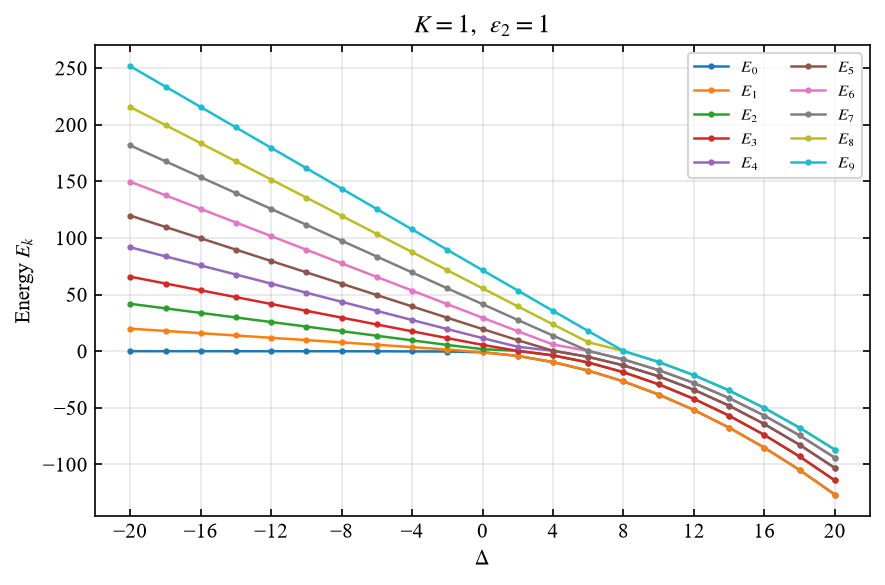

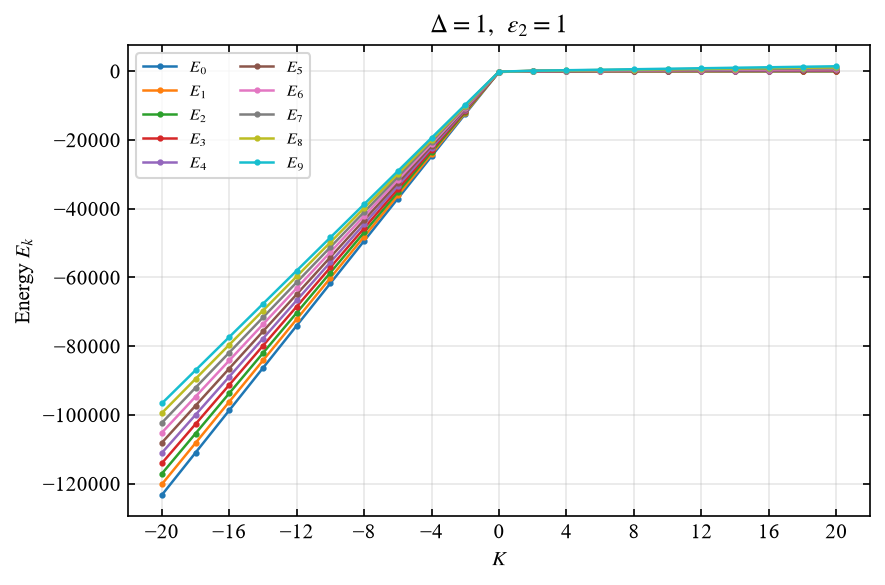

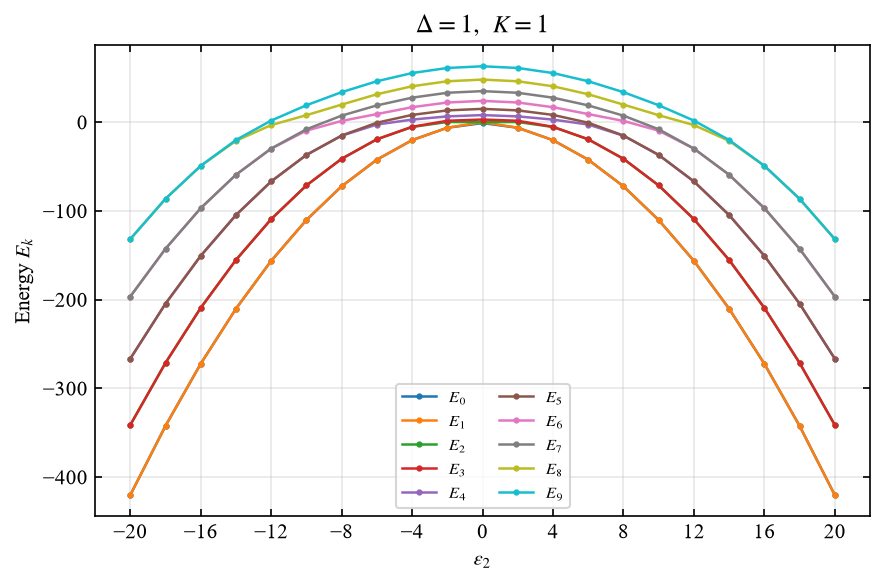

In [3]:
# Energy levels versus individual Hamiltonian parameters

# Inputs

n_fock_sweep = 80
n_levels_plot = 10

parameter_values = np.arange(-20.0, 22.0, 2.0)

#------------------------- Process -------------------------#

# Fock basis and operators
occupation_sweep = np.arange(n_fock_sweep)

a_sweep = np.diag(
    np.sqrt(occupation_sweep[1:]),
    k=1
).astype(complex)

adag_sweep = a_sweep.conj().T

n_sweep = adag_sweep @ a_sweep

kerr_operator = (
    adag_sweep @ adag_sweep @ a_sweep @ a_sweep
)

squeezing_operator = (
    adag_sweep @ adag_sweep + a_sweep @ a_sweep
)

# Independent sweeps: the two remaining parameters equal 1
sweep_configurations = [
    ('delta', r'$\Delta$', r'$K=1,\ \epsilon_2=1$'),
    ('kerr', r'$K$', r'$\Delta=1,\ \epsilon_2=1$'),
    ('epsilon_2', r'$\epsilon_2$', r'$\Delta=1,\ K=1$')
]

spectra = {}

for parameter_name, x_label, fixed_label in sweep_configurations:

    energy_spectrum = np.empty(
        (len(parameter_values), n_levels_plot)
    )

    for parameter_idx, parameter_value in enumerate(parameter_values):

        parameters = {
            'delta': 1.0,
            'kerr': 1.0,
            'epsilon_2': 1.0
        }

        parameters[parameter_name] = parameter_value

        h_matrix = (
            -parameters['delta'] * n_sweep
            + parameters['kerr'] * kerr_operator
            - parameters['epsilon_2'] * squeezing_operator
        )

        energy_spectrum[parameter_idx] = (
            np.linalg.eigvalsh(h_matrix)[:n_levels_plot]
        )

    spectra[parameter_name] = energy_spectrum

    # Outputs

    fig, ax = plt.subplots(figsize=(6.0, 4.0), dpi=150)

    for level_idx in range(n_levels_plot):

        ax.plot(
            parameter_values,
            energy_spectrum[:, level_idx],
            marker='.',
            markersize=4,
            linewidth=1.2,
            label=rf'$E_{{{level_idx}}}$'
        )

    ax.set_xlabel(x_label)
    ax.set_ylabel(r'Energy $E_k$')
    ax.set_title(fixed_label)

    ax.set_xticks(np.arange(-20, 21, 4))
    ax.grid(True, alpha=0.3)

    ax.legend(
        ncol=2,
        fontsize=8,
        frameon=True
    )

    ax.tick_params(
        axis='both',
        direction='in',
        top=True,
        right=True
    )

    fig.tight_layout()
    plt.show()

## 1st Try on conservative Hamiltonian

### **$\bullet$** Case II

#### Case and classical curves

In [ ]:
#------------------------- Inputs -------------------------#
n_fock = 64
delta = 2.0
kerr = 1.0
epsilon_2 = 5.0

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 9

#------------------------- Process -------------------------#

# Fock basis
occupation = np.arange(n_fock)
a_op = np.diag( np.sqrt(occupation[1:]), k = 1 ).astype(complex)
adag_op = a_op.conj().T
n_op = adag_op @ a_op

# Third-order operator
third_op = adag_op @ a_op @ a_op

# Kerr Hamiltonian
h_op = -delta * n_op + kerr * (adag_op @ adag_op @ a_op @ a_op) - epsilon_2 * (adag_op @ adag_op + a_op @ a_op) 

# Diagonalization
energies, eigenstates = np.linalg.eigh(h_op)

#------------------------- Outputs -------------------------#
display(Math(rf"\Delta/K = {delta/kerr}"))
display(Math(rf"2 \epsilon_2/K = {2 * epsilon_2/kerr}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

C:\Users\LUIS\AppData\Local\Temp\ipykernel_23684\1213805432.py:26: RuntimeWarning: invalid value encountered in sqrt
  p_saddle = np.sqrt((delta - 2.0 * epsilon_2) / kerr)


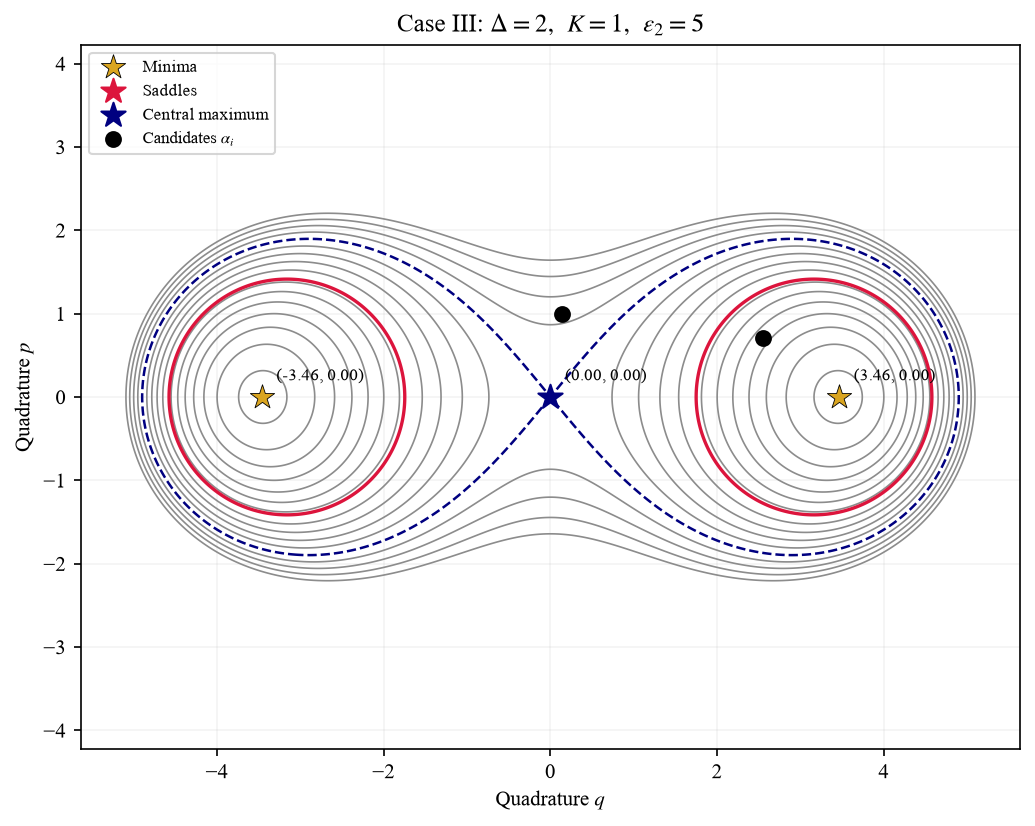

Minimum energy: -36.000000
Saddle energy: -16.000000
Central maximum energy: 0.000000
Initial centroids: (2.545584, 0.707107), (0.141421, 0.989949)
Classical energies at that point: -24.699900, 4.050000


In [ ]:
#------------------------- Phase space: Classical trajectories -------------------------#

#------------------------- Inputs -------------------------#
grid_points = 700
# Plot ranges, scaled using the current Hamiltonian parameters
q_limit = 1.15 * np.sqrt(2.0 * (delta + 2.0 * epsilon_2) / kerr)
p_limit = 0.75 * q_limit

# Candidates initial coherent amplitude, only for the marker on this map
alpha_trial = 1.8 + 0.5j
alpha_trial2 = 0.1 + 0.7j

#------------------------- Process -------------------------#

q_values = np.linspace(-q_limit, q_limit, grid_points)
p_values = np.linspace(-p_limit, p_limit, grid_points)
q_mesh, p_mesh = np.meshgrid(q_values, p_values)

def classical_energy(q, p):
    return ( -0.5 * delta * (q**2 + p**2) + 0.25 * kerr * (q**2 + p**2)**2 - epsilon_2 * (q**2 - p**2) )

energy_mesh = classical_energy(q_mesh, p_mesh)

# Stationary points and their absolute classical energies
q_minimum = np.sqrt((delta + 2.0 * epsilon_2) / kerr)
p_saddle = np.sqrt((delta - 2.0 * epsilon_2) / kerr)

energy_minimum = -(delta + 2.0 * epsilon_2)**2 / (4.0 * kerr)
energy_saddle = -(delta - 2.0 * epsilon_2)**2 / (4.0 * kerr)
energy_center = 0.0

# Regular energy contours below, between and above the critical energies
below_saddle = np.linspace( energy_minimum + 0.05 * (energy_saddle - energy_minimum),
                           energy_saddle - 0.05 * (energy_saddle - energy_minimum),
                           7 )
between_critical = np.linspace( energy_saddle, energy_center, 6 )[1:-1]
above_center = np.linspace( energy_center, 0.35 * abs(energy_minimum), 5 )[1:]

energy_levels = np.concatenate([ below_saddle, between_critical, above_center ])

# Candidate initial centroids
q_trialvec = np.sqrt(2.0) * np.array([alpha_trial.real, alpha_trial2.real])
p_trialvec = np.sqrt(2.0) * np.array([alpha_trial.imag, alpha_trial2.imag])
energy_trialvec = classical_energy(q_trialvec, p_trialvec)

#------------------------- Outputs -------------------------#
fig, ax = plt.subplots(figsize=(7.0, 5.5), dpi=150)

# Energy curves
ax.contour( q_mesh, p_mesh, energy_mesh, levels=energy_levels, colors='0.55', linewidths=0.8, linestyles='solid' )
ax.contour( q_mesh, p_mesh, energy_mesh, levels=[energy_saddle], colors='crimson', linewidths=1.6, linestyles='solid' )
ax.contour( q_mesh, p_mesh, energy_mesh, levels=[energy_center], colors='navy', linewidths=1.2, linestyles='dashed' )

# Star markers
ax.scatter( [-q_minimum, q_minimum], [0.0, 0.0], marker='*', s=150, color='goldenrod', edgecolors='black', linewidths=0.4, label='Minima', zorder=5 )
ax.scatter( [0.0, 0.0], [-p_saddle, p_saddle], marker='*', s=150, color='crimson', label='Saddles', zorder=5 )
ax.scatter( 0.0, 0.0, marker='*', s=150, color='navy', label='Central maximum', zorder=5 )

# Points
points = np.column_stack((q_trialvec, p_trialvec))
ax.scatter( points[:, 0], points[:, 1], marker='o', s=50, color='black', label=r'Candidates $\alpha_i$', zorder=6 )

# Coordinates of the stationary points
stationary_points = [
    (-q_minimum, 0.0),
    (q_minimum, 0.0),
    (0.0, -p_saddle),
    (0.0, p_saddle),
    (0.0, 0.0)
    ]

for q_point, p_point in stationary_points:
    ax.annotate( f'({q_point:.2f}, {p_point:.2f})', xy=(q_point, p_point), xytext=(7, 8), textcoords='offset points', fontsize=8 )

ax.set_xlabel(r'Quadrature $q$')
ax.set_ylabel(r'Quadrature $p$')
ax.set_title( rf'Case III: $\Delta={delta:g},\ K={kerr:g},' rf'\ \epsilon_2={epsilon_2:g}$' )
ax.set_xlim(-q_limit, q_limit)
ax.set_ylim(-p_limit, p_limit)
ax.set_aspect('equal', adjustable='box')

ax.grid(True, alpha=0.15)
ax.legend(loc='upper left', fontsize=8)

fig.tight_layout()
plt.show()

print(f"Minimum energy: {energy_minimum:.6f}")
print(f"Saddle energy: {energy_saddle:.6f}")
print(f"Central maximum energy: {energy_center:.6f}")

print(f"Initial centroids: ({q_trialvec[0]:.6f}, {p_trialvec[0]:.6f}), ({q_trialvec[1]:.6f}, {p_trialvec[1]:.6f})")
print(f"Classical energies at that point: {energy_trialvec[0]:.6f}, {energy_trialvec[1]:.6f}")

#### Evolution and spectation values for $\alpha_0$ 

In [ ]:
#------------------------- Initial state and unitary evolution -------------------------#

#------------------------- Inputs -------------------------#
t_start = 0.0
t_final = 5.0
n_times = 5001
figure_size = (10.0, 6.5)

#------------------------- Process -------------------------#
times = np.linspace(t_start, t_final, n_times)

# Coherent state in the Fock basis: ( coefficient[n] = exp(-|alpha_trial|^2/2) * alpha_trial^n / sqrt(n!) )
psi_0 = np.empty(n_fock, dtype=complex)
psi_0[0] = np.exp(- np.abs(alpha_trial)**2 / 2.0)
for n_idx in range(1, n_fock):
    psi_0[n_idx] = ( alpha_trial * psi_0[n_idx - 1] / np.sqrt(n_idx) )

# Normalization
psi_0 /= np.linalg.norm(psi_0)

# Initial amplitudes in the Hamiltonian eigenbasis
initial_coefficients = eigenstates.conj().T @ psi_0

# Time-dependent phases and evolution
phase_matrix = np.exp( -1j * energies[:, np.newaxis] * times[np.newaxis, :] )
psi_history = eigenstates @ ( initial_coefficients[:, np.newaxis] * phase_matrix )

# Expectation values of operators
def expectation_value(operator):
    return np.sum( psi_history.conj() * (operator @ psi_history), axis=0 )

exp_a = expectation_value(a_op)
exp_adag = expectation_value(adag_op)
exp_third = expectation_value(third_op)
exp_n = expectation_value(n_op).real

# Quadrature centroids, for comparison with the previous project
exp_q = np.sqrt(2.0) * exp_a.real
exp_p = np.sqrt(2.0) * exp_a.imag

Initial coherent amplitude: (1.8+0.5j)
Initial <q>: 2.545584
Initial <p>: 0.707107
Initial <n>: 3.490000


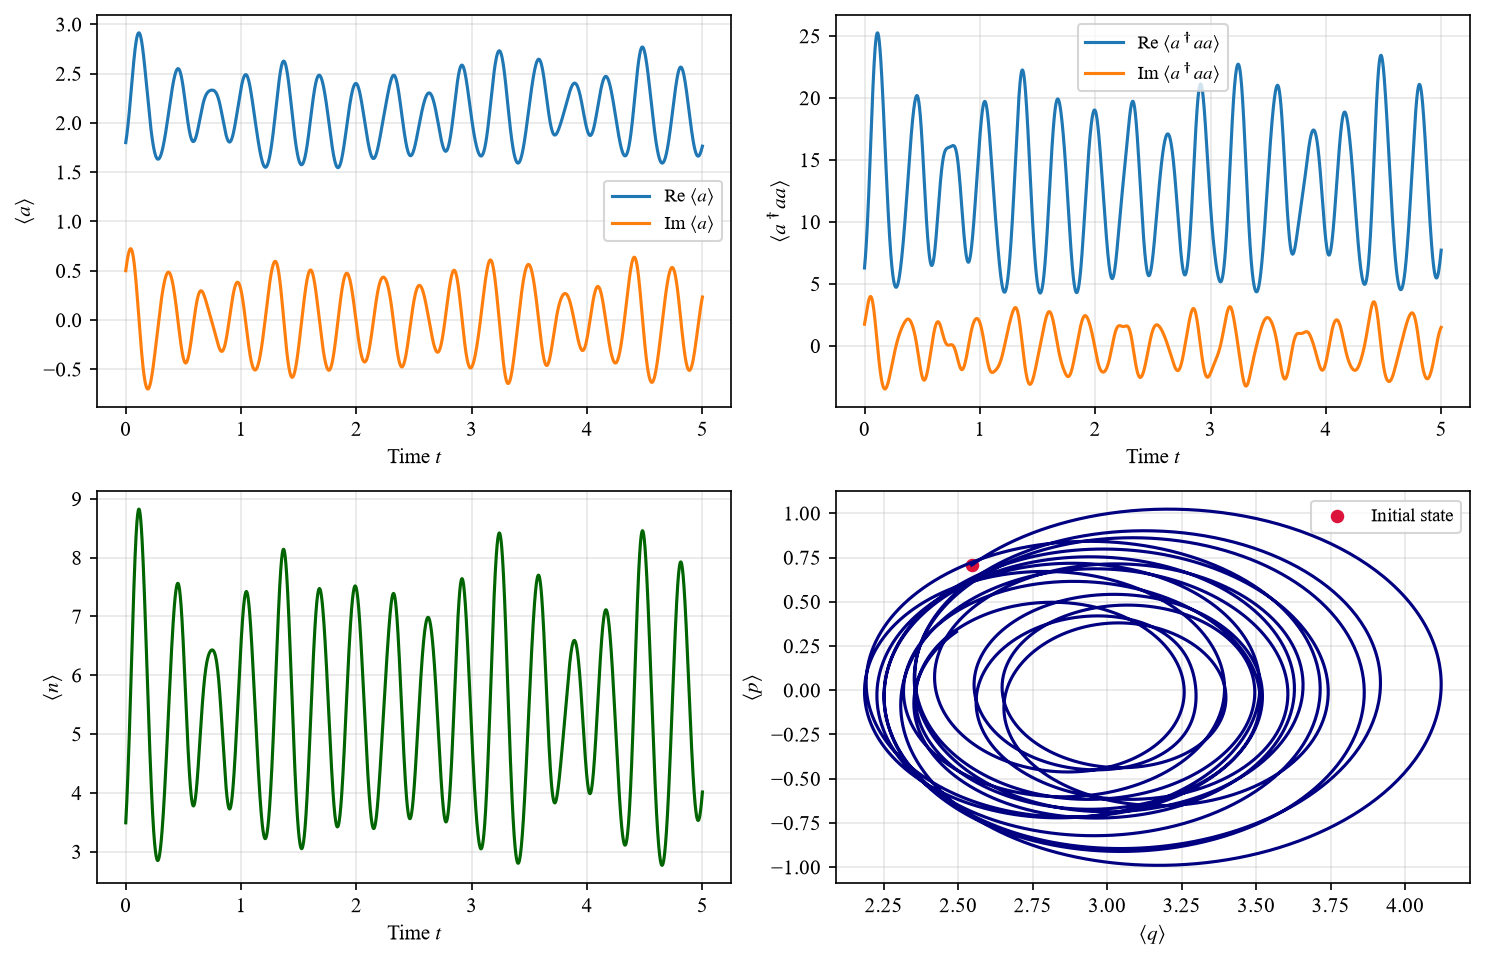

In [ ]:
#------------------------- Plots -------------------------#
fig, axes = plt.subplots(2, 2, figsize=figure_size, dpi=150)

# First-order expectation value
axes[0, 0].plot(times, exp_a.real, label=r'Re $\langle a\rangle$')
axes[0, 0].plot(times, exp_a.imag, label=r'Im $\langle a\rangle$')
axes[0, 0].set_xlabel(r'Time $t$')
axes[0, 0].set_ylabel(r'$\langle a\rangle$')
axes[0, 0].legend()

# Third-order expectation value
axes[0, 1].plot( times, exp_third.real, label=r'Re $\langle a^\dagger aa\rangle$' )
axes[0, 1].plot( times, exp_third.imag, label=r'Im $\langle a^\dagger aa\rangle$' )
axes[0, 1].set_xlabel(r'Time $t$')
axes[0, 1].set_ylabel(r'$\langle a^\dagger aa\rangle$')
axes[0, 1].legend()

# Mean occupation
axes[1, 0].plot(times, exp_n, color='darkgreen')
axes[1, 0].set_xlabel(r'Time $t$')
axes[1, 0].set_ylabel(r'$\langle n\rangle$')

# Centroid trajectory
axes[1, 1].plot(exp_q, exp_p, color='navy')
axes[1, 1].scatter( exp_q[0], exp_p[0], color='crimson', s=30, label='Initial state' )
axes[1, 1].set_xlabel(r'$\langle q\rangle$')
axes[1, 1].set_ylabel(r'$\langle p\rangle$')
axes[1, 1].legend()

for ax in axes.flat:
    ax.grid(True, alpha=0.3)

fig.tight_layout()

#------------------------- Reference values -------------------------#

print(f"Initial coherent amplitude: {alpha_trial}")
print(f"Initial <q>: {exp_q[0]:.6f}")
print(f"Initial <p>: {exp_p[0]:.6f}")
print(f"Initial <n>: {exp_n[0]:.6f}")
plt.show()

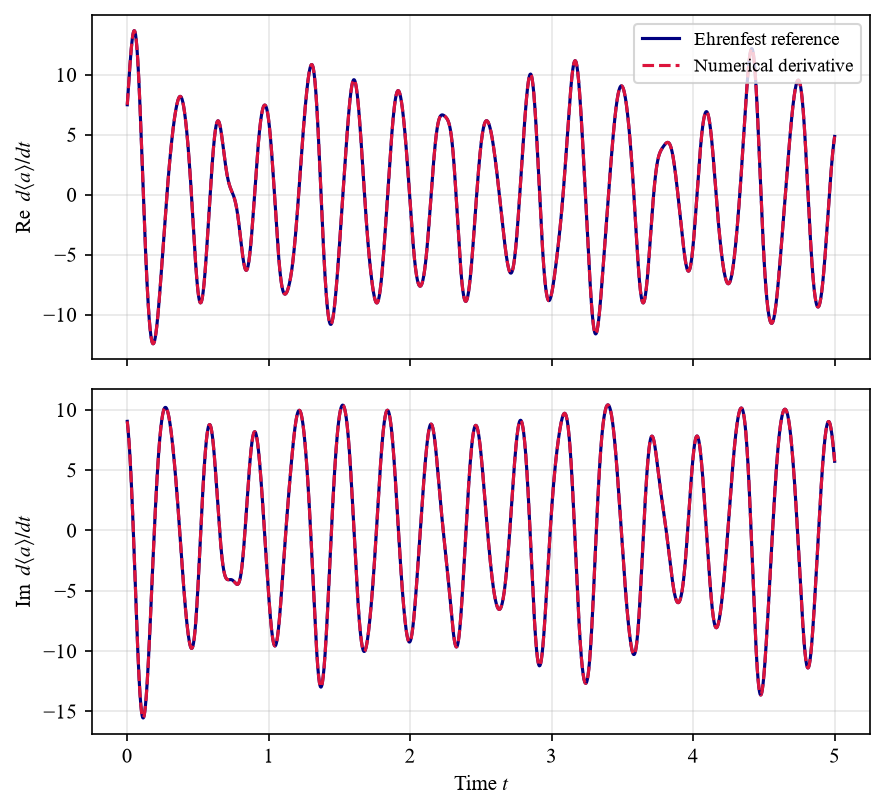

In [ ]:
#------------------------- Ehrenfest equation for the bosonic amplitude -------------------------#

# Numerical derivative of the simulated observable
dexp_a_numerical = np.gradient( exp_a, times, edge_order=2 )

# Exact bosonic equation evaluated with the measured observables
dexp_a_reference = ( 1j * delta * exp_a - 2j * kerr * exp_third + 2j * epsilon_2 * exp_adag )

fig, axes = plt.subplots( 2, 1, figsize=(6.0, 5.5), sharex=True, dpi=150 )

axes[0].plot( times, dexp_a_reference.real, color='navy', label='Ehrenfest reference' )
axes[0].plot( times, dexp_a_numerical.real, '--', color='crimson', label='Numerical derivative' )
axes[0].set_ylabel(r'Re $\,d\langle a\rangle/dt$')
axes[0].legend()

axes[1].plot( times, dexp_a_reference.imag, color='navy', label='Ehrenfest reference' )
axes[1].plot( times, dexp_a_numerical.imag, '--', color='crimson', label='Numerical derivative' )
axes[1].set_ylabel(r'Im $\,d\langle a\rangle/dt$')
axes[1].set_xlabel(r'Time $t$')

for ax in axes:
    ax.grid(True, alpha=0.3)

fig.tight_layout()

#------------------------- Output -------------------------#
plt.show()

#### Evolution and spectation values for $\alpha_1$ 

In [48]:
#------------------------- Initial state and unitary evolution -------------------------#

#------------------------- Inputs -------------------------#
t_start = 0.0
t_final = 5.0
n_times = 5001
figure_size = (10.0, 6.5)

#------------------------- Process -------------------------#
times = np.linspace(t_start, t_final, n_times)

# Coherent state in the Fock basis: ( coefficient[n] = exp(-|alpha_trial2|^2/2) * alpha_trial2^n / sqrt(n!) )
psi_0 = np.empty(n_fock, dtype=complex)
psi_0[0] = np.exp(- np.abs(alpha_trial2)**2 / 2.0)
for n_idx in range(1, n_fock):
    psi_0[n_idx] = ( alpha_trial2 * psi_0[n_idx - 1] / np.sqrt(n_idx) )

# Normalization
psi_0 /= np.linalg.norm(psi_0)

# Initial amplitudes in the Hamiltonian eigenbasis
initial_coefficients = eigenstates.conj().T @ psi_0

# Time-dependent phases and evolution
phase_matrix = np.exp( -1j * energies[:, np.newaxis] * times[np.newaxis, :] )
psi_history = eigenstates @ ( initial_coefficients[:, np.newaxis] * phase_matrix )

# Expectation values of operators
def expectation_value(operator):
    return np.sum( psi_history.conj() * (operator @ psi_history), axis=0 )

exp_a = expectation_value(a_op)
exp_adag = expectation_value(adag_op)
exp_third = expectation_value(third_op)
exp_n = expectation_value(n_op).real

# Quadrature centroids, for comparison with the previous project
exp_q = np.sqrt(2.0) * exp_a.real
exp_p = np.sqrt(2.0) * exp_a.imag

Initial coherent amplitude: (0.1+0.7j)
Initial <q>: 0.141421
Initial <p>: 0.989949
Initial <n>: 0.500000


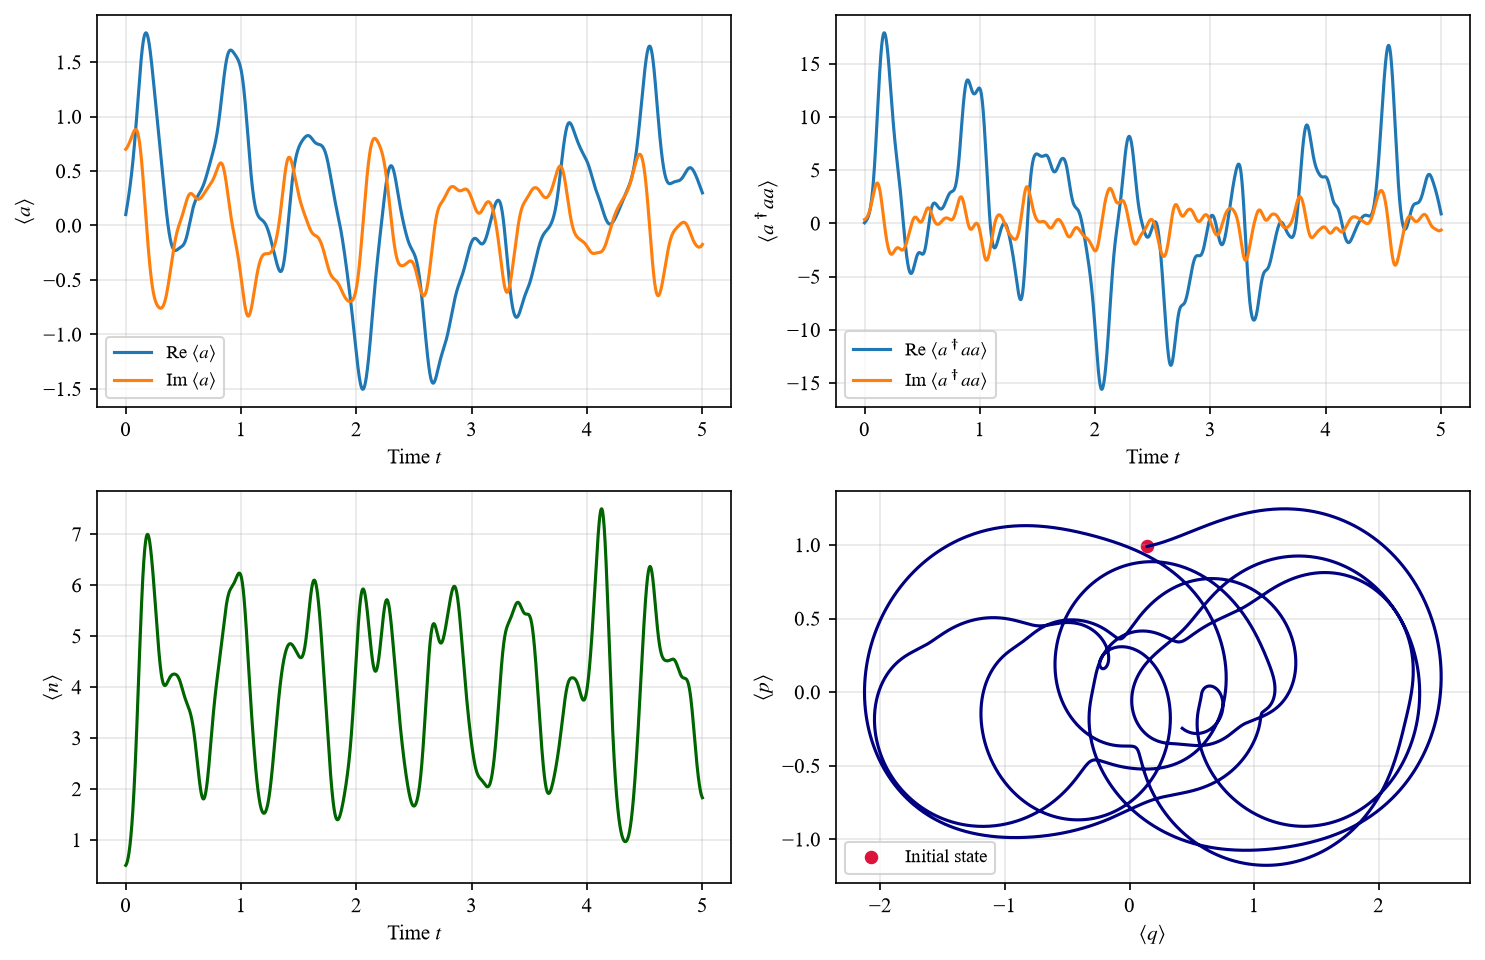

In [49]:
#------------------------- Plots -------------------------#
fig, axes = plt.subplots(2, 2, figsize=figure_size, dpi=150)

# First-order expectation value
axes[0, 0].plot(times, exp_a.real, label=r'Re $\langle a\rangle$')
axes[0, 0].plot(times, exp_a.imag, label=r'Im $\langle a\rangle$')
axes[0, 0].set_xlabel(r'Time $t$')
axes[0, 0].set_ylabel(r'$\langle a\rangle$')
axes[0, 0].legend()

# Third-order expectation value
axes[0, 1].plot( times, exp_third.real, label=r'Re $\langle a^\dagger aa\rangle$' )
axes[0, 1].plot( times, exp_third.imag, label=r'Im $\langle a^\dagger aa\rangle$' )
axes[0, 1].set_xlabel(r'Time $t$')
axes[0, 1].set_ylabel(r'$\langle a^\dagger aa\rangle$')
axes[0, 1].legend()

# Mean occupation
axes[1, 0].plot(times, exp_n, color='darkgreen')
axes[1, 0].set_xlabel(r'Time $t$')
axes[1, 0].set_ylabel(r'$\langle n\rangle$')

# Centroid trajectory
axes[1, 1].plot(exp_q, exp_p, color='navy')
axes[1, 1].scatter( exp_q[0], exp_p[0], color='crimson', s=30, label='Initial state' )
axes[1, 1].set_xlabel(r'$\langle q\rangle$')
axes[1, 1].set_ylabel(r'$\langle p\rangle$')
axes[1, 1].legend()

for ax in axes.flat:
    ax.grid(True, alpha=0.3)

fig.tight_layout()

#------------------------- Reference values -------------------------#

print(f"Initial coherent amplitude: {alpha_trial2}")
print(f"Initial <q>: {exp_q[0]:.6f}")
print(f"Initial <p>: {exp_p[0]:.6f}")
print(f"Initial <n>: {exp_n[0]:.6f}")
plt.show()

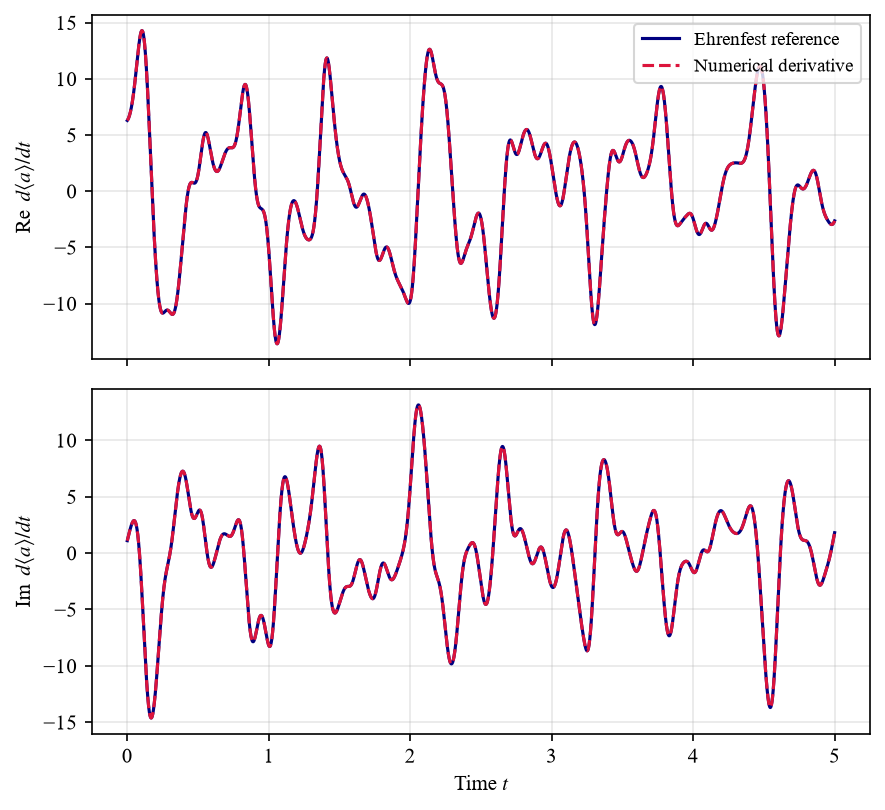

In [51]:
#------------------------- Ehrenfest equation for the bosonic amplitude -------------------------#

# Numerical derivative of the simulated observable
dexp_a_numerical = np.gradient( exp_a, times, edge_order=2 )

# Exact bosonic equation evaluated with the measured observables
dexp_a_reference = ( 1j * delta * exp_a - 2j * kerr * exp_third + 2j * epsilon_2 * exp_adag )

fig, axes = plt.subplots( 2, 1, figsize=(6.0, 5.5), sharex=True, dpi=150 )

axes[0].plot( times, dexp_a_reference.real, color='navy', label='Ehrenfest reference' )
axes[0].plot( times, dexp_a_numerical.real, '--', color='crimson', label='Numerical derivative' )
axes[0].set_ylabel(r'Re $\,d\langle a\rangle/dt$')
axes[0].legend()

axes[1].plot( times, dexp_a_reference.imag, color='navy', label='Ehrenfest reference' )
axes[1].plot( times, dexp_a_numerical.imag, '--', color='crimson', label='Numerical derivative' )
axes[1].set_ylabel(r'Im $\,d\langle a\rangle/dt$')
axes[1].set_xlabel(r'Time $t$')

for ax in axes:
    ax.grid(True, alpha=0.3)

fig.tight_layout()

#------------------------- Output -------------------------#
plt.show()

### **$\bullet$** Case III

#### Case and classical curves

In [3]:
#------------------------- Inputs -------------------------#
n_fock = 64
delta = 9.0
kerr = 1.0
epsilon_2 = 3.0

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 9

#------------------------- Process -------------------------#

# Fock basis
occupation = np.arange(n_fock)
a_op = np.diag( np.sqrt(occupation[1:]), k = 1 ).astype(complex)
adag_op = a_op.conj().T
n_op = adag_op @ a_op

# Third-order operator
third_op = adag_op @ a_op @ a_op

# Kerr Hamiltonian
h_op = -delta * n_op + kerr * (adag_op @ adag_op @ a_op @ a_op) - epsilon_2 * (adag_op @ adag_op + a_op @ a_op) 

# Diagonalization
energies, eigenstates = np.linalg.eigh(h_op)

#------------------------- Outputs -------------------------#
display(Math(rf"\Delta/K = {delta/kerr}"))
display(Math(rf"2 \epsilon_2/K = {2 * epsilon_2/kerr}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

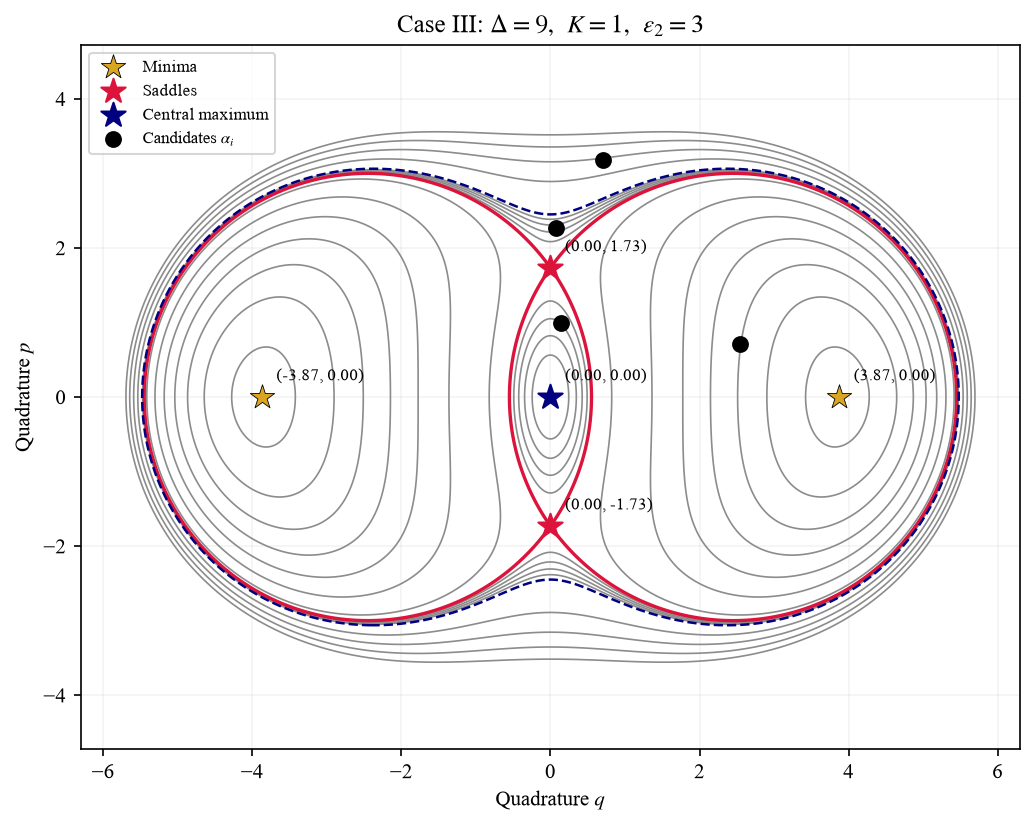

Minimum energy: -56.250000
Saddle energy: -2.250000
Central maximum energy: 0.000000
Initial centroids: (2.545584, 0.707107), (0.141421, 0.989949), (0.070711, 2.262742), (0.707107, 3.181981)
Classical energies at that point: -37.169900, -1.370000, -1.151094, 9.285156


In [10]:
#------------------------- Phase space: Classical trajectories -------------------------#

#------------------------- Inputs -------------------------#
grid_points = 700
# Plot ranges, scaled using the current Hamiltonian parameters
q_limit = 1.15 * np.sqrt(2.0 * (delta + 2.0 * epsilon_2) / kerr)
p_limit = 0.75 * q_limit

# Candidates initial coherent amplitude, only for the marker on this map
alpha_trial = 1.8 + 0.5j
alpha_trial2 = 0.1 + 0.7j
alpha_trial3 = 0.05 + 1.6j
alpha_trial4 = 0.5 + 2.25j

#------------------------- Process -------------------------#

q_values = np.linspace(-q_limit, q_limit, grid_points)
p_values = np.linspace(-p_limit, p_limit, grid_points)
q_mesh, p_mesh = np.meshgrid(q_values, p_values)

def classical_energy(q, p):
    return ( -0.5 * delta * (q**2 + p**2) + 0.25 * kerr * (q**2 + p**2)**2 - epsilon_2 * (q**2 - p**2) )

energy_mesh = classical_energy(q_mesh, p_mesh)

# Stationary points and their absolute classical energies
q_minimum = np.sqrt((delta + 2.0 * epsilon_2) / kerr)
p_saddle = np.sqrt((delta - 2.0 * epsilon_2) / kerr)

energy_minimum = -(delta + 2.0 * epsilon_2)**2 / (4.0 * kerr)
energy_saddle = -(delta - 2.0 * epsilon_2)**2 / (4.0 * kerr)
energy_center = 0.0

# Regular energy contours below, between and above the critical energies
below_saddle = np.linspace( energy_minimum + 0.05 * (energy_saddle - energy_minimum),
                           energy_saddle - 0.05 * (energy_saddle - energy_minimum),
                           7 )
between_critical = np.linspace( energy_saddle, energy_center, 6 )[1:-1]
above_center = np.linspace( energy_center, 0.35 * abs(energy_minimum), 5 )[1:]

energy_levels = np.concatenate([ below_saddle, between_critical, above_center ])

# Candidate initial centroids
q_trialvec = np.sqrt(2.0) * np.array([alpha_trial.real, alpha_trial2.real, alpha_trial3.real, alpha_trial4.real])
p_trialvec = np.sqrt(2.0) * np.array([alpha_trial.imag, alpha_trial2.imag, alpha_trial3.imag, alpha_trial4.imag])
energy_trialvec = classical_energy(q_trialvec, p_trialvec)

#------------------------- Outputs -------------------------#
fig, ax = plt.subplots(figsize=(7.0, 5.5), dpi=150)

# Energy curves
ax.contour( q_mesh, p_mesh, energy_mesh, levels=energy_levels, colors='0.55', linewidths=0.8, linestyles='solid' )
ax.contour( q_mesh, p_mesh, energy_mesh, levels=[energy_saddle], colors='crimson', linewidths=1.6, linestyles='solid' )
ax.contour( q_mesh, p_mesh, energy_mesh, levels=[energy_center], colors='navy', linewidths=1.2, linestyles='dashed' )

# Star markers
ax.scatter( [-q_minimum, q_minimum], [0.0, 0.0], marker='*', s=150, color='goldenrod', edgecolors='black', linewidths=0.4, label='Minima', zorder=5 )
ax.scatter( [0.0, 0.0], [-p_saddle, p_saddle], marker='*', s=150, color='crimson', label='Saddles', zorder=5 )
ax.scatter( 0.0, 0.0, marker='*', s=150, color='navy', label='Central maximum', zorder=5 )

# Points
points = np.column_stack((q_trialvec, p_trialvec))
ax.scatter( points[:, 0], points[:, 1], marker='o', s=50, color='black', label=r'Candidates $\alpha_i$', zorder=6 )

# Coordinates of the stationary points
stationary_points = [
    (-q_minimum, 0.0),
    (q_minimum, 0.0),
    (0.0, -p_saddle),
    (0.0, p_saddle),
    (0.0, 0.0)
    ]

for q_point, p_point in stationary_points:
    ax.annotate( f'({q_point:.2f}, {p_point:.2f})', xy=(q_point, p_point), xytext=(7, 8), textcoords='offset points', fontsize=8 )

ax.set_xlabel(r'Quadrature $q$')
ax.set_ylabel(r'Quadrature $p$')
ax.set_title( rf'Case III: $\Delta={delta:g},\ K={kerr:g},' rf'\ \epsilon_2={epsilon_2:g}$' )
ax.set_xlim(-q_limit, q_limit)
ax.set_ylim(-p_limit, p_limit)
ax.set_aspect('equal', adjustable='box')

ax.grid(True, alpha=0.15)
ax.legend(loc='upper left', fontsize=8)

fig.tight_layout()
plt.show()

print(f"Minimum energy: {energy_minimum:.6f}")
print(f"Saddle energy: {energy_saddle:.6f}")
print(f"Central maximum energy: {energy_center:.6f}")

print(f"Initial centroids: ({q_trialvec[0]:.6f}, {p_trialvec[0]:.6f}), ({q_trialvec[1]:.6f}, {p_trialvec[1]:.6f}), ({q_trialvec[2]:.6f}, {p_trialvec[2]:.6f}), ({q_trialvec[3]:.6f}, {p_trialvec[3]:.6f})")
print(f"Classical energies at that point: {energy_trialvec[0]:.6f}, {energy_trialvec[1]:.6f}, {energy_trialvec[2]:.6f}, {energy_trialvec[3]:.6f}")

#### Evolution and spectation values for $\alpha_0$ 

In [26]:
#------------------------- Initial state and unitary evolution -------------------------#

#------------------------- Inputs -------------------------#
t_start = 0.0
t_final = 5.0
n_times = 5001
figure_size = (10.0, 6.5)

#------------------------- Process -------------------------#
times = np.linspace(t_start, t_final, n_times)

# Coherent state in the Fock basis: ( coefficient[n] = exp(-|alpha_trial|^2/2) * alpha_trial^n / sqrt(n!) )
psi_0 = np.empty(n_fock, dtype=complex)
psi_0[0] = np.exp(- np.abs(alpha_trial)**2 / 2.0)
for n_idx in range(1, n_fock):
    psi_0[n_idx] = ( alpha_trial * psi_0[n_idx - 1] / np.sqrt(n_idx) )

# Normalization
psi_0 /= np.linalg.norm(psi_0)

# Initial amplitudes in the Hamiltonian eigenbasis
initial_coefficients = eigenstates.conj().T @ psi_0

# Time-dependent phases and evolution
phase_matrix = np.exp( -1j * energies[:, np.newaxis] * times[np.newaxis, :] )
psi_history = eigenstates @ ( initial_coefficients[:, np.newaxis] * phase_matrix )

# Expectation values of operators
def expectation_value(operator):
    return np.sum( psi_history.conj() * (operator @ psi_history), axis=0 )

exp_a = expectation_value(a_op)
exp_adag = expectation_value(adag_op)
exp_third = expectation_value(third_op)
exp_n = expectation_value(n_op).real

# Quadrature centroids, for comparison with the previous project
exp_q = np.sqrt(2.0) * exp_a.real
exp_p = np.sqrt(2.0) * exp_a.imag

Initial coherent amplitude: (1.8+0.5j)
Initial <q>: 2.545584
Initial <p>: 0.707107
Initial <n>: 3.490000


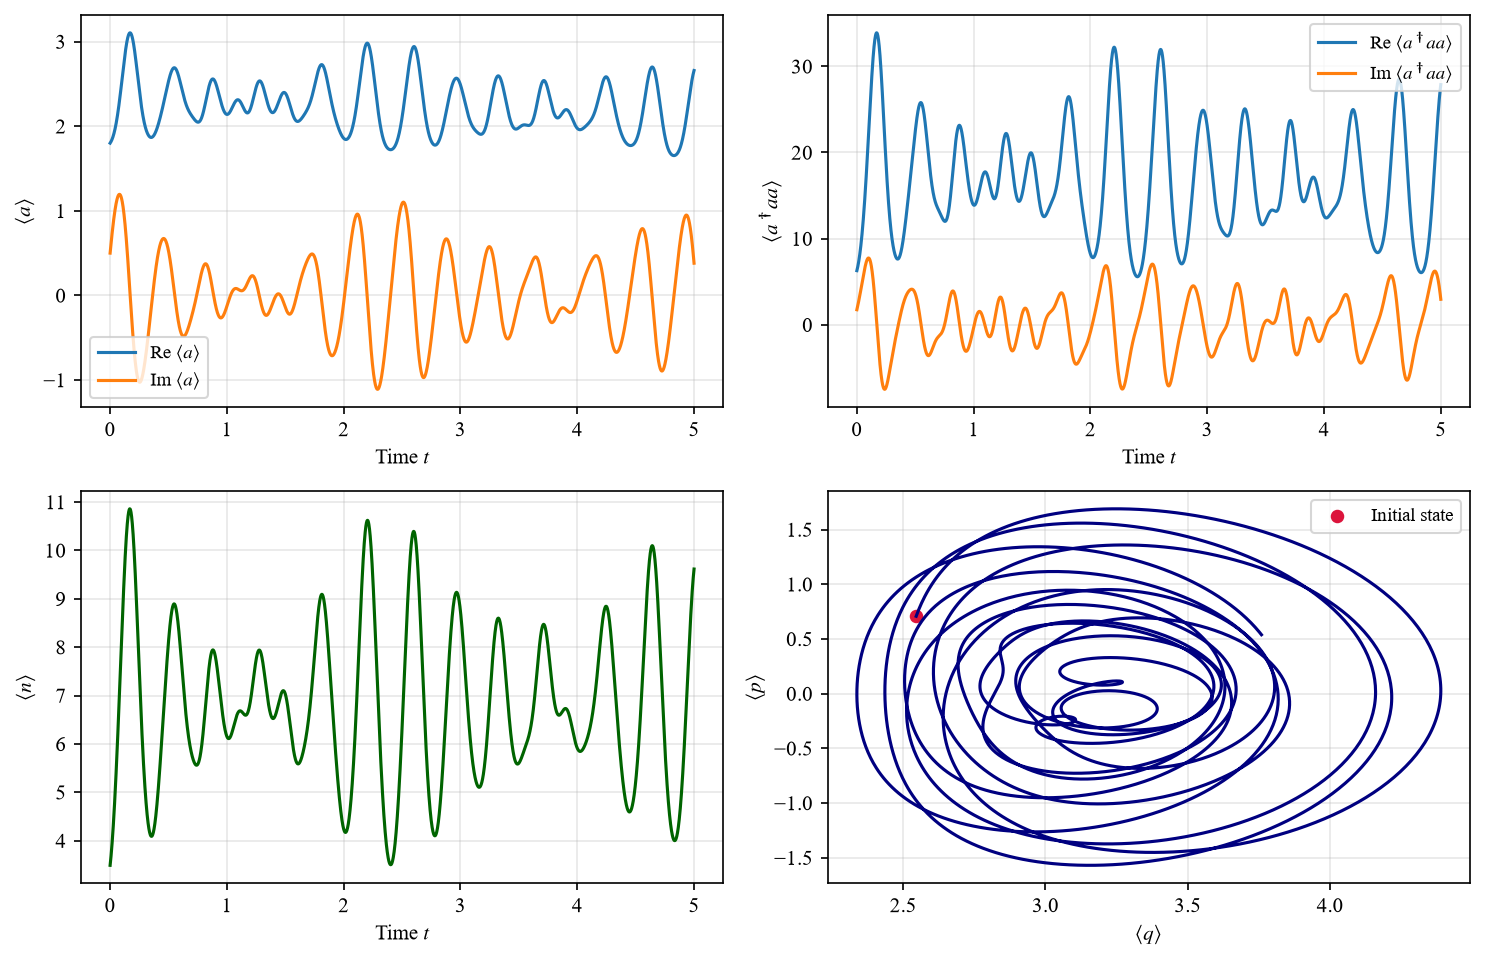

In [27]:
#------------------------- Plots -------------------------#
fig, axes = plt.subplots(2, 2, figsize=figure_size, dpi=150)

# First-order expectation value
axes[0, 0].plot(times, exp_a.real, label=r'Re $\langle a\rangle$')
axes[0, 0].plot(times, exp_a.imag, label=r'Im $\langle a\rangle$')
axes[0, 0].set_xlabel(r'Time $t$')
axes[0, 0].set_ylabel(r'$\langle a\rangle$')
axes[0, 0].legend()

# Third-order expectation value
axes[0, 1].plot( times, exp_third.real, label=r'Re $\langle a^\dagger aa\rangle$' )
axes[0, 1].plot( times, exp_third.imag, label=r'Im $\langle a^\dagger aa\rangle$' )
axes[0, 1].set_xlabel(r'Time $t$')
axes[0, 1].set_ylabel(r'$\langle a^\dagger aa\rangle$')
axes[0, 1].legend()

# Mean occupation
axes[1, 0].plot(times, exp_n, color='darkgreen')
axes[1, 0].set_xlabel(r'Time $t$')
axes[1, 0].set_ylabel(r'$\langle n\rangle$')

# Centroid trajectory
axes[1, 1].plot(exp_q, exp_p, color='navy')
axes[1, 1].scatter( exp_q[0], exp_p[0], color='crimson', s=30, label='Initial state' )
axes[1, 1].set_xlabel(r'$\langle q\rangle$')
axes[1, 1].set_ylabel(r'$\langle p\rangle$')
axes[1, 1].legend()

for ax in axes.flat:
    ax.grid(True, alpha=0.3)

fig.tight_layout()

#------------------------- Reference values -------------------------#

print(f"Initial coherent amplitude: {alpha_trial}")
print(f"Initial <q>: {exp_q[0]:.6f}")
print(f"Initial <p>: {exp_p[0]:.6f}")
print(f"Initial <n>: {exp_n[0]:.6f}")
plt.show()

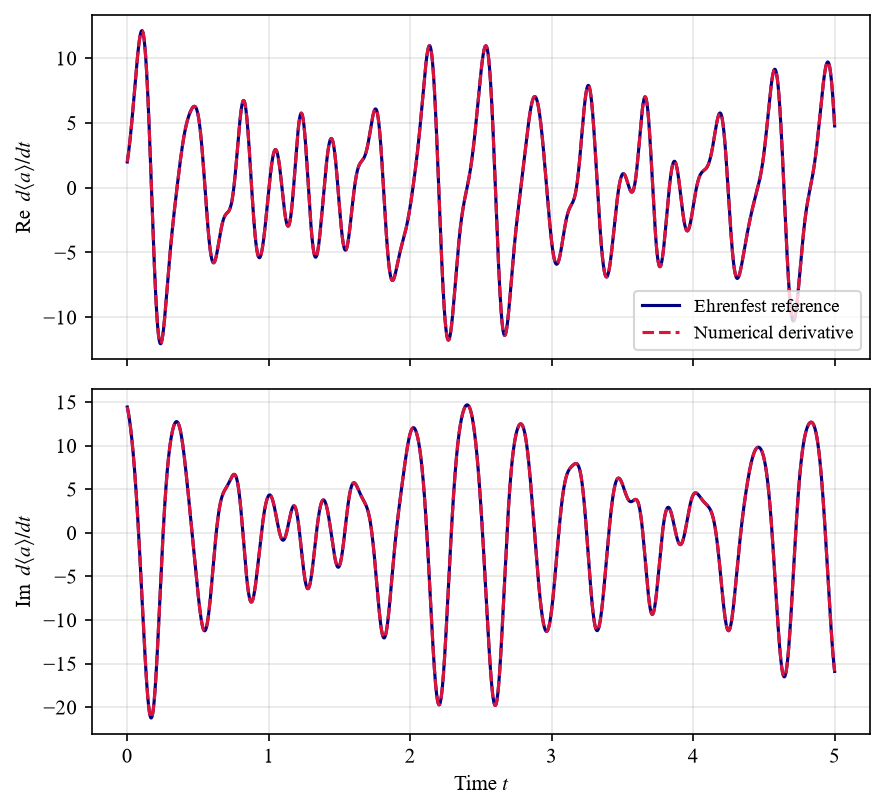

In [28]:
#------------------------- Ehrenfest equation for the bosonic amplitude -------------------------#

# Numerical derivative of the simulated observable
dexp_a_numerical = np.gradient( exp_a, times, edge_order=2 )

# Exact bosonic equation evaluated with the measured observables
dexp_a_reference = ( 1j * delta * exp_a - 2j * kerr * exp_third + 2j * epsilon_2 * exp_adag )

fig, axes = plt.subplots( 2, 1, figsize=(6.0, 5.5), sharex=True, dpi=150 )

axes[0].plot( times, dexp_a_reference.real, color='navy', label='Ehrenfest reference' )
axes[0].plot( times, dexp_a_numerical.real, '--', color='crimson', label='Numerical derivative' )
axes[0].set_ylabel(r'Re $\,d\langle a\rangle/dt$')
axes[0].legend()

axes[1].plot( times, dexp_a_reference.imag, color='navy', label='Ehrenfest reference' )
axes[1].plot( times, dexp_a_numerical.imag, '--', color='crimson', label='Numerical derivative' )
axes[1].set_ylabel(r'Im $\,d\langle a\rangle/dt$')
axes[1].set_xlabel(r'Time $t$')

for ax in axes:
    ax.grid(True, alpha=0.3)

fig.tight_layout()

#------------------------- Output -------------------------#
plt.show()

#### Evolution and spectation values for $\alpha_1$ 

In [38]:
#------------------------- Initial state and unitary evolution -------------------------#

#------------------------- Inputs -------------------------#
t_start = 0.0
t_final = 5.0
n_times = 5001
figure_size = (10.0, 6.5)

#------------------------- Process -------------------------#
times = np.linspace(t_start, t_final, n_times)

# Coherent state in the Fock basis: ( coefficient[n] = exp(-|alpha_trial2|^2/2) * alpha_trial2^n / sqrt(n!) )
psi_0 = np.empty(n_fock, dtype=complex)
psi_0[0] = np.exp(- np.abs(alpha_trial2)**2 / 2.0)
for n_idx in range(1, n_fock):
    psi_0[n_idx] = ( alpha_trial2 * psi_0[n_idx - 1] / np.sqrt(n_idx) )

# Normalization
psi_0 /= np.linalg.norm(psi_0)

# Initial amplitudes in the Hamiltonian eigenbasis
initial_coefficients = eigenstates.conj().T @ psi_0

# Time-dependent phases and evolution
phase_matrix = np.exp( -1j * energies[:, np.newaxis] * times[np.newaxis, :] )
psi_history = eigenstates @ ( initial_coefficients[:, np.newaxis] * phase_matrix )

# Expectation values of operators
def expectation_value(operator):
    return np.sum( psi_history.conj() * (operator @ psi_history), axis=0 )

exp_a = expectation_value(a_op)
exp_adag = expectation_value(adag_op)
exp_third = expectation_value(third_op)
exp_n = expectation_value(n_op).real

# Quadrature centroids, for comparison with the previous project
exp_q = np.sqrt(2.0) * exp_a.real
exp_p = np.sqrt(2.0) * exp_a.imag

Initial coherent amplitude: (0.1+0.7j)
Initial <q>: 0.141421
Initial <p>: 0.989949
Initial <n>: 0.500000


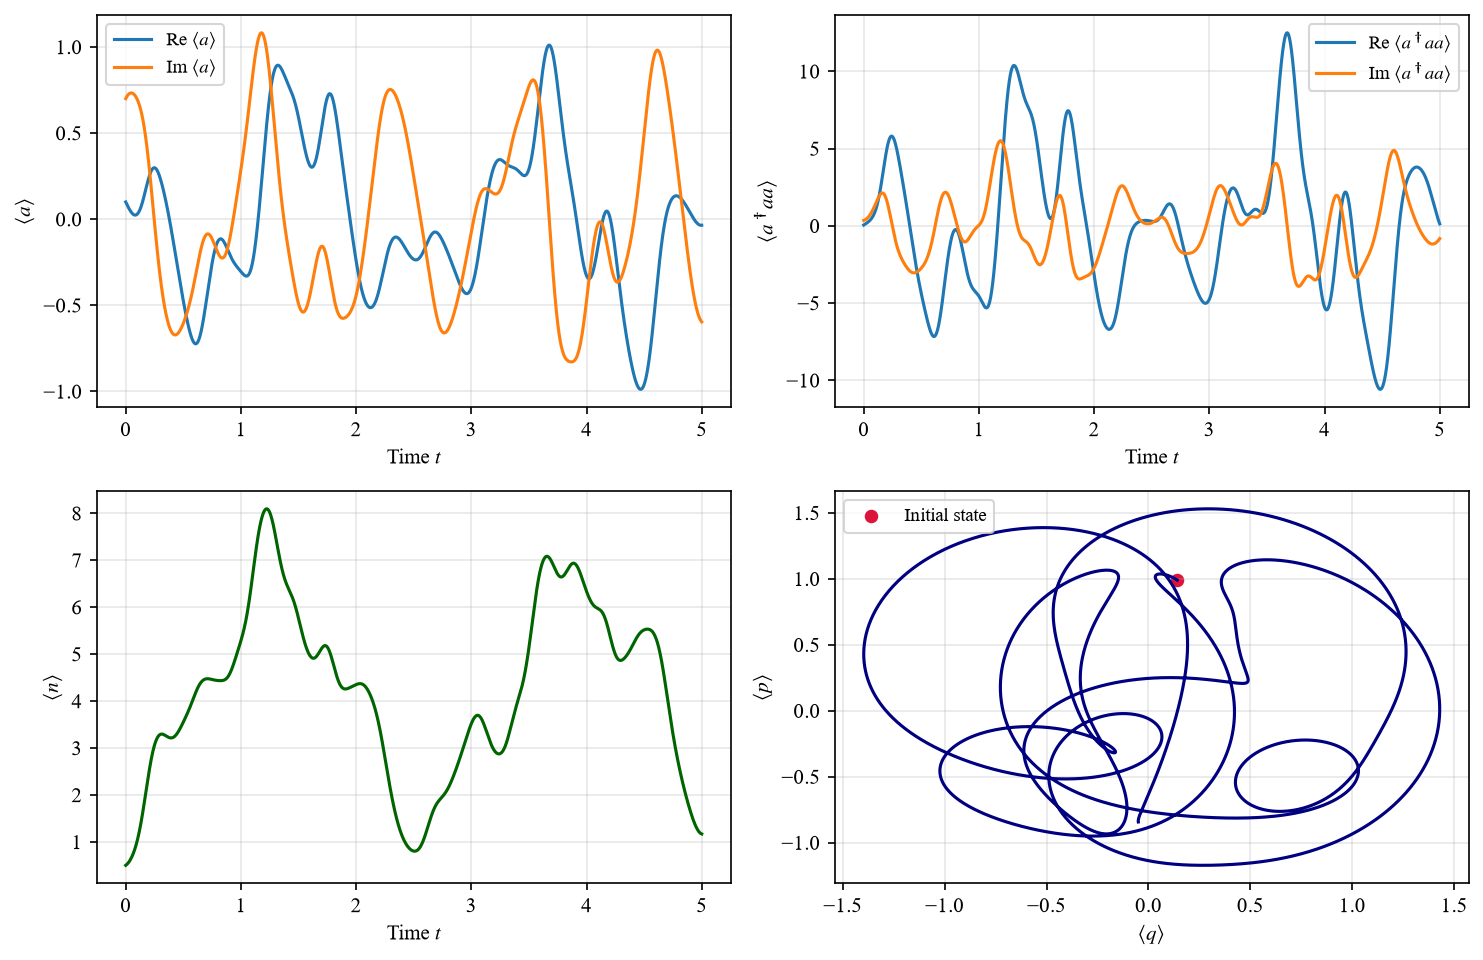

In [39]:
#------------------------- Plots -------------------------#
fig, axes = plt.subplots(2, 2, figsize=figure_size, dpi=150)

# First-order expectation value
axes[0, 0].plot(times, exp_a.real, label=r'Re $\langle a\rangle$')
axes[0, 0].plot(times, exp_a.imag, label=r'Im $\langle a\rangle$')
axes[0, 0].set_xlabel(r'Time $t$')
axes[0, 0].set_ylabel(r'$\langle a\rangle$')
axes[0, 0].legend()

# Third-order expectation value
axes[0, 1].plot( times, exp_third.real, label=r'Re $\langle a^\dagger aa\rangle$' )
axes[0, 1].plot( times, exp_third.imag, label=r'Im $\langle a^\dagger aa\rangle$' )
axes[0, 1].set_xlabel(r'Time $t$')
axes[0, 1].set_ylabel(r'$\langle a^\dagger aa\rangle$')
axes[0, 1].legend()

# Mean occupation
axes[1, 0].plot(times, exp_n, color='darkgreen')
axes[1, 0].set_xlabel(r'Time $t$')
axes[1, 0].set_ylabel(r'$\langle n\rangle$')

# Centroid trajectory
axes[1, 1].plot(exp_q, exp_p, color='navy')
axes[1, 1].scatter( exp_q[0], exp_p[0], color='crimson', s=30, label='Initial state' )
axes[1, 1].set_xlabel(r'$\langle q\rangle$')
axes[1, 1].set_ylabel(r'$\langle p\rangle$')
axes[1, 1].legend()

for ax in axes.flat:
    ax.grid(True, alpha=0.3)

fig.tight_layout()

#------------------------- Reference values -------------------------#

print(f"Initial coherent amplitude: {alpha_trial2}")
print(f"Initial <q>: {exp_q[0]:.6f}")
print(f"Initial <p>: {exp_p[0]:.6f}")
print(f"Initial <n>: {exp_n[0]:.6f}")
plt.show()

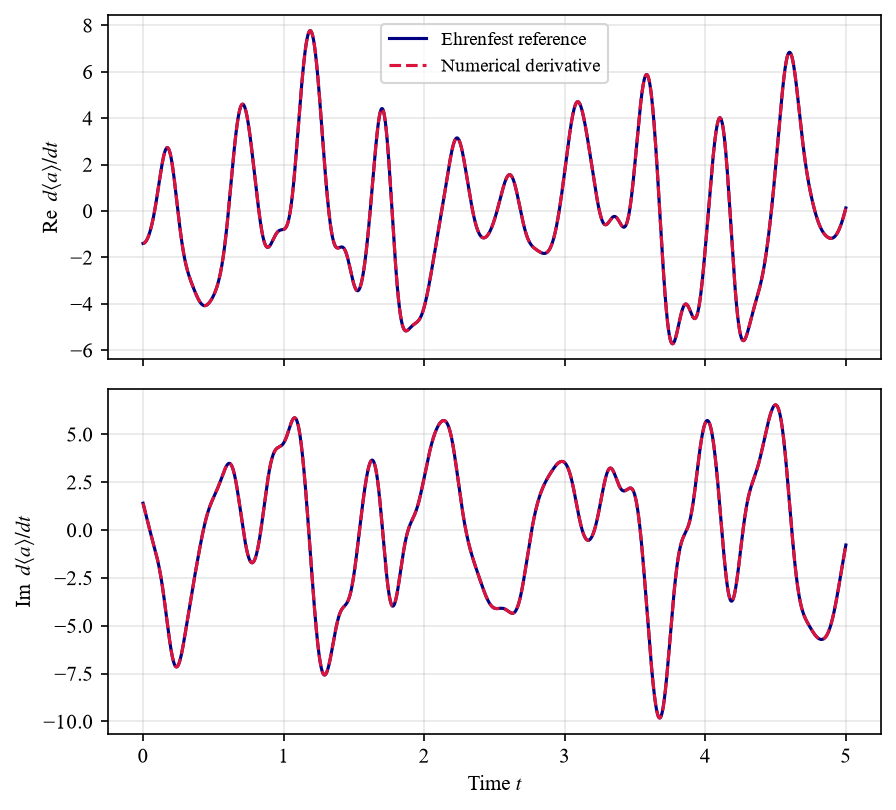

In [40]:
#------------------------- Ehrenfest equation for the bosonic amplitude -------------------------#

# Numerical derivative of the simulated observable
dexp_a_numerical = np.gradient( exp_a, times, edge_order=2 )

# Exact bosonic equation evaluated with the measured observables
dexp_a_reference = ( 1j * delta * exp_a - 2j * kerr * exp_third + 2j * epsilon_2 * exp_adag )

fig, axes = plt.subplots( 2, 1, figsize=(6.0, 5.5), sharex=True, dpi=150 )

axes[0].plot( times, dexp_a_reference.real, color='navy', label='Ehrenfest reference' )
axes[0].plot( times, dexp_a_numerical.real, '--', color='crimson', label='Numerical derivative' )
axes[0].set_ylabel(r'Re $\,d\langle a\rangle/dt$')
axes[0].legend()

axes[1].plot( times, dexp_a_reference.imag, color='navy', label='Ehrenfest reference' )
axes[1].plot( times, dexp_a_numerical.imag, '--', color='crimson', label='Numerical derivative' )
axes[1].set_ylabel(r'Im $\,d\langle a\rangle/dt$')
axes[1].set_xlabel(r'Time $t$')

for ax in axes:
    ax.grid(True, alpha=0.3)

fig.tight_layout()

#------------------------- Output -------------------------#
plt.show()

#### Evolution and spectation values for $\alpha_2$ 

In [35]:
#------------------------- Initial state and unitary evolution -------------------------#

#------------------------- Inputs -------------------------#
t_start = 0.0
t_final = 5.0
n_times = 5001
figure_size = (10.0, 6.5)

#------------------------- Process -------------------------#
times = np.linspace(t_start, t_final, n_times)

# Coherent state in the Fock basis: ( coefficient[n] = exp(-|alpha_trial3|^2/2) * alpha_trial3^n / sqrt(n!) )
psi_0 = np.empty(n_fock, dtype=complex)
psi_0[0] = np.exp(- np.abs(alpha_trial3)**2 / 2.0)
for n_idx in range(1, n_fock):
    psi_0[n_idx] = ( alpha_trial3 * psi_0[n_idx - 1] / np.sqrt(n_idx) )

# Normalization
psi_0 /= np.linalg.norm(psi_0)

# Initial amplitudes in the Hamiltonian eigenbasis
initial_coefficients = eigenstates.conj().T @ psi_0

# Time-dependent phases and evolution
phase_matrix = np.exp( -1j * energies[:, np.newaxis] * times[np.newaxis, :] )
psi_history = eigenstates @ ( initial_coefficients[:, np.newaxis] * phase_matrix )

# Expectation values of operators
def expectation_value(operator):
    return np.sum( psi_history.conj() * (operator @ psi_history), axis=0 )

exp_a = expectation_value(a_op)
exp_adag = expectation_value(adag_op)
exp_third = expectation_value(third_op)
exp_n = expectation_value(n_op).real

# Quadrature centroids, for comparison with the previous project
exp_q = np.sqrt(2.0) * exp_a.real
exp_p = np.sqrt(2.0) * exp_a.imag

Initial coherent amplitude: (0.05+1.6j)
Initial <q>: 0.070711
Initial <p>: 2.262742
Initial <n>: 2.562500


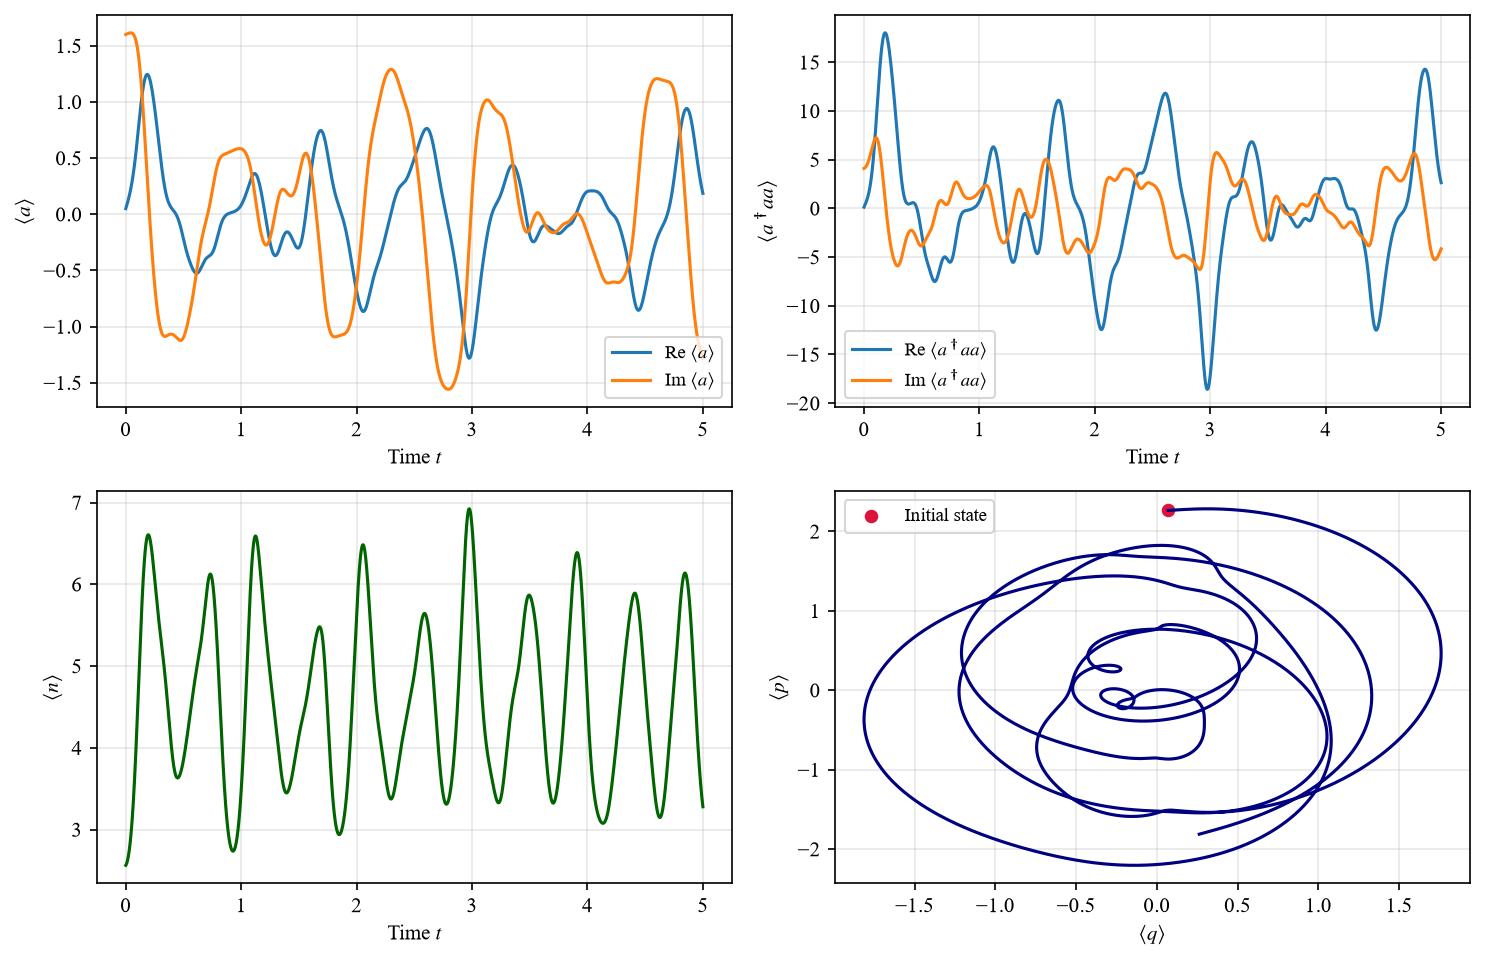

In [36]:
#------------------------- Plots -------------------------#
fig, axes = plt.subplots(2, 2, figsize=figure_size, dpi=150)

# First-order expectation value
axes[0, 0].plot(times, exp_a.real, label=r'Re $\langle a\rangle$')
axes[0, 0].plot(times, exp_a.imag, label=r'Im $\langle a\rangle$')
axes[0, 0].set_xlabel(r'Time $t$')
axes[0, 0].set_ylabel(r'$\langle a\rangle$')
axes[0, 0].legend()

# Third-order expectation value
axes[0, 1].plot( times, exp_third.real, label=r'Re $\langle a^\dagger aa\rangle$' )
axes[0, 1].plot( times, exp_third.imag, label=r'Im $\langle a^\dagger aa\rangle$' )
axes[0, 1].set_xlabel(r'Time $t$')
axes[0, 1].set_ylabel(r'$\langle a^\dagger aa\rangle$')
axes[0, 1].legend()

# Mean occupation
axes[1, 0].plot(times, exp_n, color='darkgreen')
axes[1, 0].set_xlabel(r'Time $t$')
axes[1, 0].set_ylabel(r'$\langle n\rangle$')

# Centroid trajectory
axes[1, 1].plot(exp_q, exp_p, color='navy')
axes[1, 1].scatter( exp_q[0], exp_p[0], color='crimson', s=30, label='Initial state' )
axes[1, 1].set_xlabel(r'$\langle q\rangle$')
axes[1, 1].set_ylabel(r'$\langle p\rangle$')
axes[1, 1].legend()

for ax in axes.flat:
    ax.grid(True, alpha=0.3)

fig.tight_layout()

#------------------------- Reference values -------------------------#

print(f"Initial coherent amplitude: {alpha_trial3}")
print(f"Initial <q>: {exp_q[0]:.6f}")
print(f"Initial <p>: {exp_p[0]:.6f}")
print(f"Initial <n>: {exp_n[0]:.6f}")
plt.show()

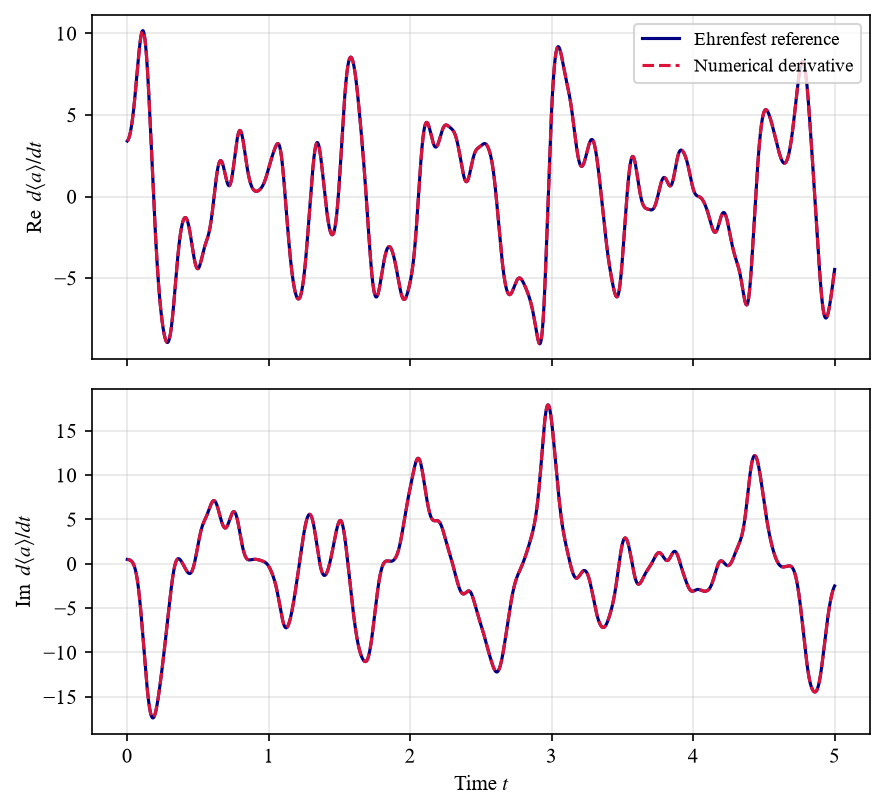

In [37]:
#------------------------- Ehrenfest equation for the bosonic amplitude -------------------------#

# Numerical derivative of the simulated observable
dexp_a_numerical = np.gradient( exp_a, times, edge_order=2 )

# Exact bosonic equation evaluated with the measured observables
dexp_a_reference = ( 1j * delta * exp_a - 2j * kerr * exp_third + 2j * epsilon_2 * exp_adag )

fig, axes = plt.subplots( 2, 1, figsize=(6.0, 5.5), sharex=True, dpi=150 )

axes[0].plot( times, dexp_a_reference.real, color='navy', label='Ehrenfest reference' )
axes[0].plot( times, dexp_a_numerical.real, '--', color='crimson', label='Numerical derivative' )
axes[0].set_ylabel(r'Re $\,d\langle a\rangle/dt$')
axes[0].legend()

axes[1].plot( times, dexp_a_reference.imag, color='navy', label='Ehrenfest reference' )
axes[1].plot( times, dexp_a_numerical.imag, '--', color='crimson', label='Numerical derivative' )
axes[1].set_ylabel(r'Im $\,d\langle a\rangle/dt$')
axes[1].set_xlabel(r'Time $t$')

for ax in axes:
    ax.grid(True, alpha=0.3)

fig.tight_layout()

#------------------------- Output -------------------------#
plt.show()

#### Evolution and spectation values for $\alpha_3$ 

In [32]:
#------------------------- Initial state and unitary evolution -------------------------#

#------------------------- Inputs -------------------------#
t_start = 0.0
t_final = 5.0
n_times = 5001
figure_size = (10.0, 6.5)

#------------------------- Process -------------------------#
times = np.linspace(t_start, t_final, n_times)

# Coherent state in the Fock basis: ( coefficient[n] = exp(-|alpha_trial4|^2/2) * alpha_trial4^n / sqrt(n!) )
psi_0 = np.empty(n_fock, dtype=complex)
psi_0[0] = np.exp(- np.abs(alpha_trial4)**2 / 2.0)
for n_idx in range(1, n_fock):
    psi_0[n_idx] = ( alpha_trial4 * psi_0[n_idx - 1] / np.sqrt(n_idx) )

# Normalization
psi_0 /= np.linalg.norm(psi_0)

# Initial amplitudes in the Hamiltonian eigenbasis
initial_coefficients = eigenstates.conj().T @ psi_0

# Time-dependent phases and evolution
phase_matrix = np.exp( -1j * energies[:, np.newaxis] * times[np.newaxis, :] )
psi_history = eigenstates @ ( initial_coefficients[:, np.newaxis] * phase_matrix )

# Expectation values of operators
def expectation_value(operator):
    return np.sum( psi_history.conj() * (operator @ psi_history), axis=0 )

exp_a = expectation_value(a_op)
exp_adag = expectation_value(adag_op)
exp_third = expectation_value(third_op)
exp_n = expectation_value(n_op).real

# Quadrature centroids, for comparison with the previous project
exp_q = np.sqrt(2.0) * exp_a.real
exp_p = np.sqrt(2.0) * exp_a.imag

Initial coherent amplitude: (0.5+2.25j)
Initial <q>: 0.707107
Initial <p>: 3.181981
Initial <n>: 5.312500


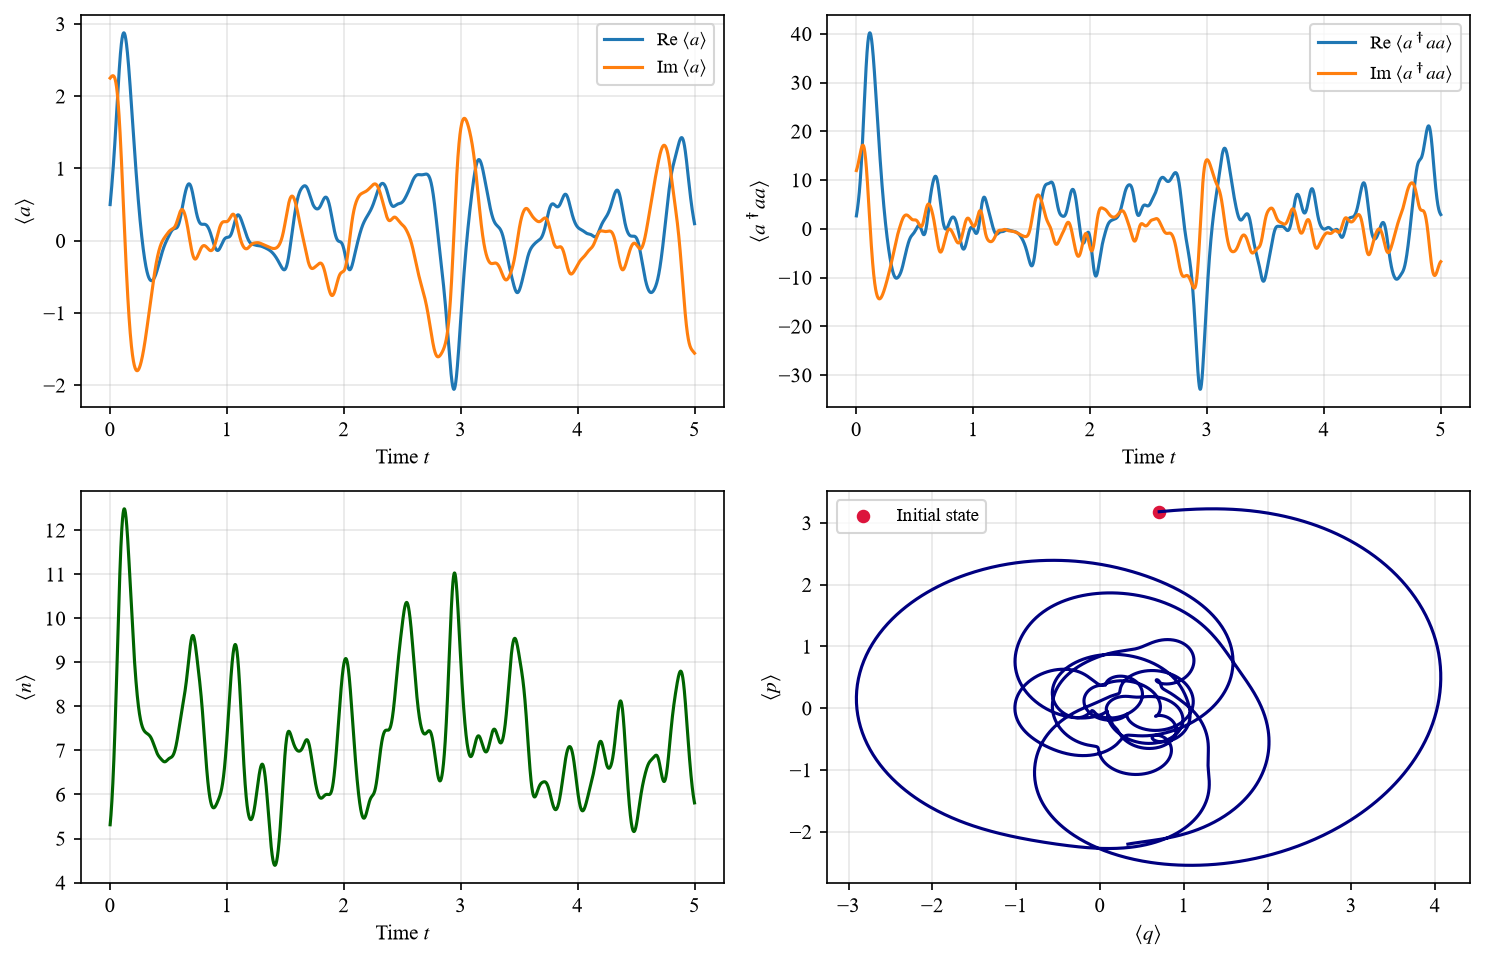

In [33]:
#------------------------- Plots -------------------------#
fig, axes = plt.subplots(2, 2, figsize=figure_size, dpi=150)

# First-order expectation value
axes[0, 0].plot(times, exp_a.real, label=r'Re $\langle a\rangle$')
axes[0, 0].plot(times, exp_a.imag, label=r'Im $\langle a\rangle$')
axes[0, 0].set_xlabel(r'Time $t$')
axes[0, 0].set_ylabel(r'$\langle a\rangle$')
axes[0, 0].legend()

# Third-order expectation value
axes[0, 1].plot( times, exp_third.real, label=r'Re $\langle a^\dagger aa\rangle$' )
axes[0, 1].plot( times, exp_third.imag, label=r'Im $\langle a^\dagger aa\rangle$' )
axes[0, 1].set_xlabel(r'Time $t$')
axes[0, 1].set_ylabel(r'$\langle a^\dagger aa\rangle$')
axes[0, 1].legend()

# Mean occupation
axes[1, 0].plot(times, exp_n, color='darkgreen')
axes[1, 0].set_xlabel(r'Time $t$')
axes[1, 0].set_ylabel(r'$\langle n\rangle$')

# Centroid trajectory
axes[1, 1].plot(exp_q, exp_p, color='navy')
axes[1, 1].scatter( exp_q[0], exp_p[0], color='crimson', s=30, label='Initial state' )
axes[1, 1].set_xlabel(r'$\langle q\rangle$')
axes[1, 1].set_ylabel(r'$\langle p\rangle$')
axes[1, 1].legend()

for ax in axes.flat:
    ax.grid(True, alpha=0.3)

fig.tight_layout()

#------------------------- Reference values -------------------------#

print(f"Initial coherent amplitude: {alpha_trial4}")
print(f"Initial <q>: {exp_q[0]:.6f}")
print(f"Initial <p>: {exp_p[0]:.6f}")
print(f"Initial <n>: {exp_n[0]:.6f}")
plt.show()

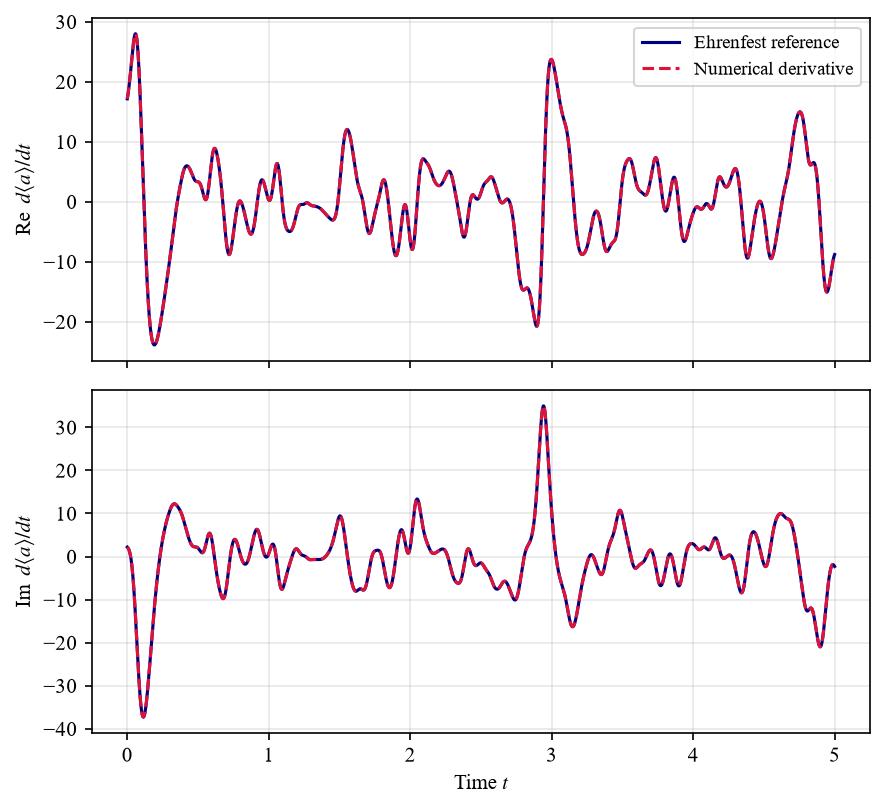

In [34]:
#------------------------- Ehrenfest equation for the bosonic amplitude -------------------------#

# Numerical derivative of the simulated observable
dexp_a_numerical = np.gradient( exp_a, times, edge_order=2 )

# Exact bosonic equation evaluated with the measured observables
dexp_a_reference = ( 1j * delta * exp_a - 2j * kerr * exp_third + 2j * epsilon_2 * exp_adag )

fig, axes = plt.subplots( 2, 1, figsize=(6.0, 5.5), sharex=True, dpi=150 )

axes[0].plot( times, dexp_a_reference.real, color='navy', label='Ehrenfest reference' )
axes[0].plot( times, dexp_a_numerical.real, '--', color='crimson', label='Numerical derivative' )
axes[0].set_ylabel(r'Re $\,d\langle a\rangle/dt$')
axes[0].legend()

axes[1].plot( times, dexp_a_reference.imag, color='navy', label='Ehrenfest reference' )
axes[1].plot( times, dexp_a_numerical.imag, '--', color='crimson', label='Numerical derivative' )
axes[1].set_ylabel(r'Im $\,d\langle a\rangle/dt$')
axes[1].set_xlabel(r'Time $t$')

for ax in axes:
    ax.grid(True, alpha=0.3)

fig.tight_layout()

#------------------------- Output -------------------------#
plt.show()

## **$\bullet$** 2nd Try of SINDy on conservative Hamiltonian

### **->** Case III: Inside right well

#### ~ System configs

In [6]:
#------------------------- Inputs and settings -------------------------#
n_fock = 64
delta = 9.0
kerr = 1.0
epsilon_2 = 3.0

alpha_0 = 1.8 + 0.5j

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 9


#------------------------- Process -------------------------#
occupation = np.arange(n_fock)

a_op = np.diag( np.sqrt(occupation[1:]), k=1 ).astype(complex)
adag_op = a_op.conj().T
n_op = adag_op @ a_op
third_op = adag_op @ a_op @ a_op

h_op = ( -delta * n_op + kerr * (adag_op @ adag_op @ a_op @ a_op) - epsilon_2 * (adag_op @ adag_op + a_op @ a_op) )

energies, eigenstates = np.linalg.eigh(h_op)

#### ~ Expectation values evolution

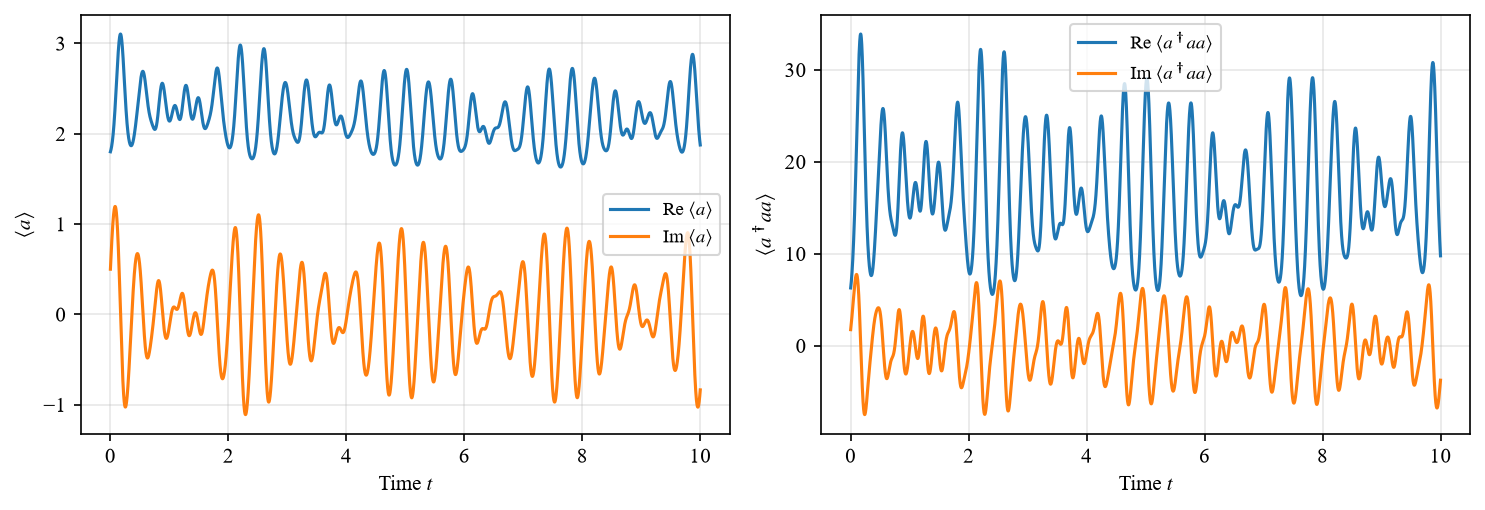

In [10]:
#------------------------- Inputs -------------------------#
t_start = 0.0
t_final = 10.0
n_times = 10001


#------------------------- Process -------------------------#
times = np.linspace(t_start, t_final, n_times)
dt = times[1] - times[0]

# Initial coherent state
psi_0 = np.empty(n_fock, dtype=complex)
psi_0[0] = np.exp(-np.abs(alpha_0)**2 / 2.0)

for n_idx in range(1, n_fock):
    psi_0[n_idx] = ( alpha_0 * psi_0[n_idx - 1] / np.sqrt(n_idx) )

psi_0 /= np.linalg.norm(psi_0)

# Unitary evolution
initial_coefficients = eigenstates.conj().T @ psi_0

phase_matrix = np.exp( -1j * energies[:, np.newaxis] * times[np.newaxis, :] )

psi_history = eigenstates @ ( initial_coefficients[:, np.newaxis] * phase_matrix )

def expectation_value(operator):
    return np.sum( psi_history.conj() * (operator @ psi_history), axis=0 )

exp_a = expectation_value(a_op)
exp_adag = expectation_value(adag_op)
exp_third = expectation_value(third_op)
exp_n = expectation_value(n_op).real


#------------------------- Outputs -------------------------#
fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.5), dpi=150)

axes[0].plot(times, exp_a.real, label=r'Re $\langle a\rangle$')
axes[0].plot(times, exp_a.imag, label=r'Im $\langle a\rangle$')
axes[0].set_ylabel(r'$\langle a\rangle$')

axes[1].plot( times, exp_third.real, label=r'Re $\langle a^\dagger aa\rangle$' )
axes[1].plot( times, exp_third.imag, label=r'Im $\langle a^\dagger aa\rangle$' )
axes[1].set_ylabel(r'$\langle a^\dagger aa\rangle$')

for ax in axes:
    ax.set_xlabel(r'Time $t$')
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()
plt.show()

#### ~ SINDy build

In [ ]:
#------------------------- Inputs -------------------------#
t_train_max = 2.0
threshold = 1e-3
max_iterations = 25

def build_library(a_values, third_values):
    a_values = np.atleast_1d(a_values)
    third_values = np.atleast_1d(third_values)

    feature_dict = {
        '1': np.ones_like(a_values),
        '<a>': a_values,
        '<adag>': np.conj(a_values),
        '<a>^2': a_values**2,
        '<adag>^2': np.conj(a_values)**2,
        '|<a>|^2': np.abs(a_values)**2,
        '|<a>|^2*<a>': np.abs(a_values)**2 * a_values,
        '<adag*a*a>': third_values
    }

    return ( np.column_stack(list(feature_dict.values())), list(feature_dict.keys()) )


#------------------------- Process -------------------------#
# Training window
training_indices = np.where(times <= t_train_max)[0]
a_training = exp_a[training_indices]
third_training = exp_third[training_indices]

# Fourth-order centered differences.
# Discard two samples at each boundary.
a_dot_training = ( -a_training[4:] + 8.0 * a_training[3:-1] - 8.0 * a_training[1:-3] + a_training[:-4] ) / (12.0 * dt)

theta_mat, feature_names = build_library( a_training[2:-2], third_training[2:-2] )

# Initial least-squares estimate: complex coefficients
xi = np.linalg.lstsq( theta_mat, a_dot_training, rcond=None )[0]

# Sequential thresholding and refitting
for iteration in range(max_iterations):

    active_terms = np.abs(xi) >= threshold
    xi[~active_terms] = 0.0

    if np.any(active_terms):

        xi[active_terms] = np.linalg.lstsq( theta_mat[:, active_terms], a_dot_training, rcond=None )[0]

residuals = a_dot_training - theta_mat @ xi
training_mse = np.mean(np.abs(residuals)**2)


#------------------------- Outputs -------------------------#
print(f"Training samples: {len(a_dot_training)}")
print(f"Threshold: {threshold:.3e}")
print(f"Training MSE: {training_mse:.6e}")

print("\nIdentified equation: d<a>/dt =")

for name, coefficient in zip(feature_names, xi):

    if np.abs(coefficient) > 0:

        print(
            f" ({coefficient.real:+.8f}"
            f"{coefficient.imag:+.8f}j) * {name}"
            )

print("\nTheoretical reference:")
print(f"  ({1j * delta}) * <a>")
print(f"  ({2j * epsilon_2}) * <adag>")
print(f"  ({-2j * kerr}) * <adag*a*a>")

Training samples: 1997
Threshold: 1.000e-03
Training MSE: 1.743308e-14

Identified equation: d<a>/dt =
 (+0.00000000+8.99999991j) * <a>
 (+0.00000000+5.99999997j) * <adag>
 (-0.00000000-1.99999998j) * <adag*a*a>

Theoretical reference:
  (9j) * <a>
  (6j) * <adag>
  ((-0-2j)) * <adag*a*a>


#### ~ Graphics

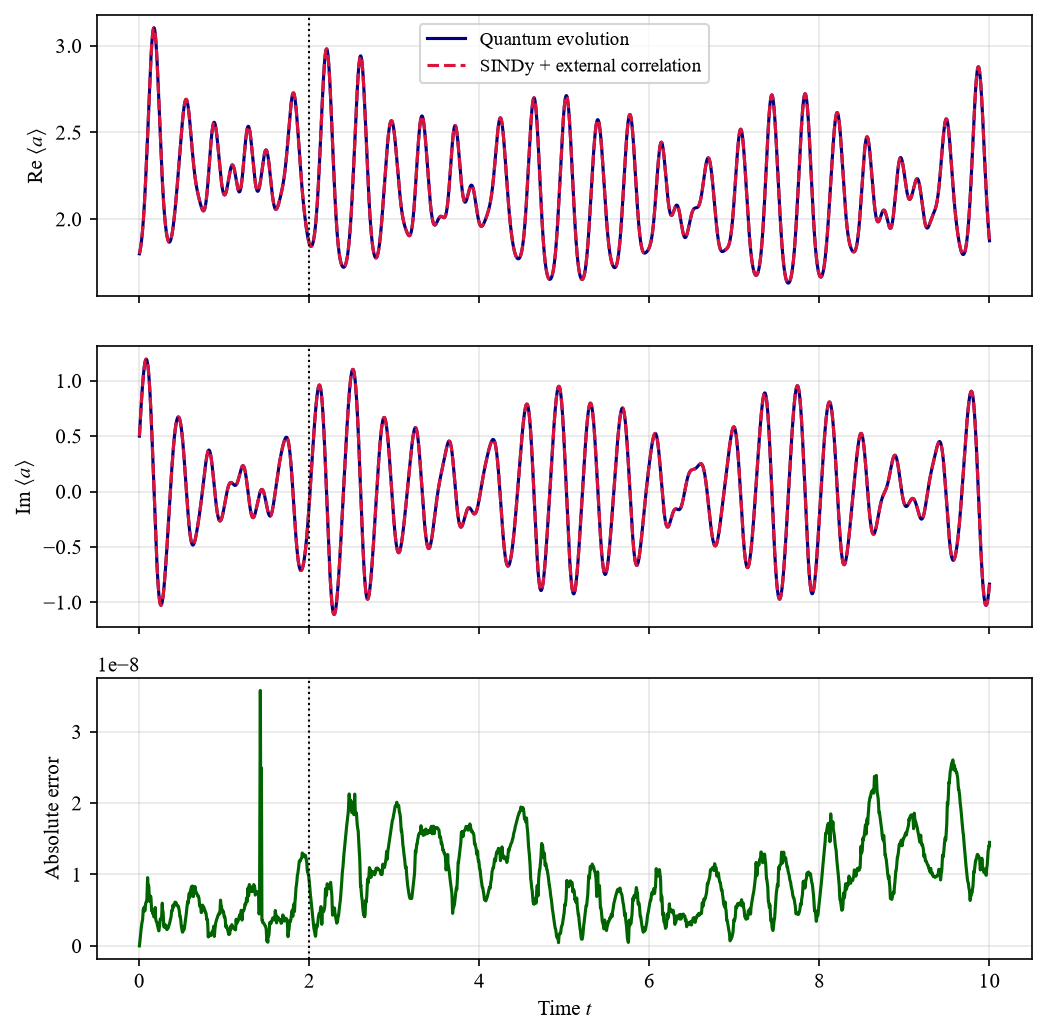

Maximum amplitude error: 3.576753e-08
Maximum error after training: 2.605208e-08


In [9]:
#------------------------- Inputs -------------------------# 
rtol = 1e-9
atol = 1e-11

#------------------------- Process -------------------------# 
third_interpolator = interp1d( times, exp_third, kind='cubic', bounds_error=True )

def sindy_dynamics(t_value, state):

    a_value = state[0] + 1j * state[1]
    third_value = third_interpolator(t_value)

    theta_row, _ = build_library( np.array([a_value]), np.array([third_value]) )

    a_dot = (theta_row @ xi)[0]

    return [a_dot.real, a_dot.imag]


solution = solve_ivp(
    sindy_dynamics,
    t_span=(times[0], times[-1]),
    y0=[exp_a[0].real, exp_a[0].imag],
    t_eval=times,
    method='DOP853',
    rtol=rtol,
    atol=atol
    )

if not solution.success:
    raise RuntimeError(solution.message)

exp_a_sindy = solution.y[0] + 1j * solution.y[1]
absolute_error = np.abs(exp_a_sindy - exp_a)

#------------------------- Outputs -------------------------#
fig, axes = plt.subplots( 3, 1, figsize=(7.0, 7.0), sharex=True, dpi=150 )

axes[0].plot( times, exp_a.real, color='navy', label='Quantum evolution' )
axes[0].plot( times, exp_a_sindy.real, '--', color='crimson', label='SINDy + external correlation' )
axes[0].set_ylabel(r'Re $\langle a\rangle$')
axes[0].legend()

axes[1].plot(times, exp_a.imag, color='navy')
axes[1].plot( times, exp_a_sindy.imag, '--', color='crimson' )
axes[1].set_ylabel(r'Im $\langle a\rangle$')

axes[2].plot(times, absolute_error, color='darkgreen')
axes[2].set_ylabel('Absolute error')
axes[2].set_xlabel(r'Time $t$')

for ax in axes:
    ax.axvline( t_train_max, color='black', linestyle=':', linewidth=1.0 )
    ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

print(f"Maximum amplitude error: {np.max(absolute_error):.6e}")

future_mask = times > t_train_max

print( "Maximum error after training: " f"{np.max(absolute_error[future_mask]):.6e}" )

#### ~ Now $X$ $P$ basis

In [ ]:
#------------------------- Inputs -------------------------#
t_train_max = 2.0
threshold = 1e-3
max_iterations = 25


#------------------------- Process -------------------------#
exp_q = np.sqrt(2.0) * exp_a.real
exp_p = np.sqrt(2.0) * exp_a.imag

def build_qp_library(q_values, p_values, third_values):
    q_values = np.atleast_1d(q_values)
    p_values = np.atleast_1d(p_values)
    third_values = np.atleast_1d(third_values)

    feature_dict = {
        '1': np.ones_like(q_values),
        'q': q_values,
        'p': p_values,
        'q^2': q_values**2,
        'q*p': q_values * p_values,
        'p^2': p_values**2,
        'q^3': q_values**3,
        'q^2*p': q_values**2 * p_values,
        'q*p^2': q_values * p_values**2,
        'p^3': p_values**3,
        'Re<C>': third_values.real,
        'Im<C>': third_values.imag
        }

    return ( np.column_stack(list(feature_dict.values())), list(feature_dict.keys()) )

training_indices = np.where(times <= t_train_max)[0]
dt = times[1] - times[0]

# Two columns: position and momentum centroids
qp_training = np.column_stack([ exp_q[training_indices], exp_p[training_indices] ])

third_training = exp_third[training_indices]

# Numerical derivatives of both signals
qp_dot_training = ( -qp_training[4:] + 8.0 * qp_training[3:-1] - 8.0 * qp_training[1:-3] + qp_training[:-4] ) / (12.0 * dt)

theta_qp, feature_names_qp = build_qp_library( qp_training[2:-2, 0], qp_training[2:-2, 1], third_training[2:-2] )

# One coefficient column for each equation
xi_qp = np.linalg.lstsq( theta_qp, qp_dot_training, rcond=None )[0]

# Sequential thresholding and refitting
for iteration in range(max_iterations):

    active_terms = np.abs(xi_qp) >= threshold
    xi_qp[~active_terms] = 0.0

    for equation_idx in range(2):

        active_columns = active_terms[:, equation_idx]

        if np.any(active_columns):

            xi_qp[active_columns, equation_idx] = np.linalg.lstsq( theta_qp[:, active_columns], qp_dot_training[:, equation_idx], rcond=None )[0]

residuals_qp = qp_dot_training - theta_qp @ xi_qp
training_mse_qp = np.mean(residuals_qp**2)


#------------------------- Outputs -------------------------#
print(f"Training MSE: {training_mse_qp:.6e}")

for equation_idx, equation_name in enumerate(['dq/dt', 'dp/dt']):

    print(f"\n{equation_name} =")

    for name, coefficient in zip( feature_names_qp, xi_qp[:, equation_idx] ):

        if coefficient != 0.0:
            print(f"({coefficient:+.8f}) * {name}")

Training MSE: 1.253290e-14

dq/dt =
  (-2.99999946) * p
  (+2.82842700) * Im<C>

dp/dt =
  (+14.99999991) * q
  (-2.82842711) * Re<C>


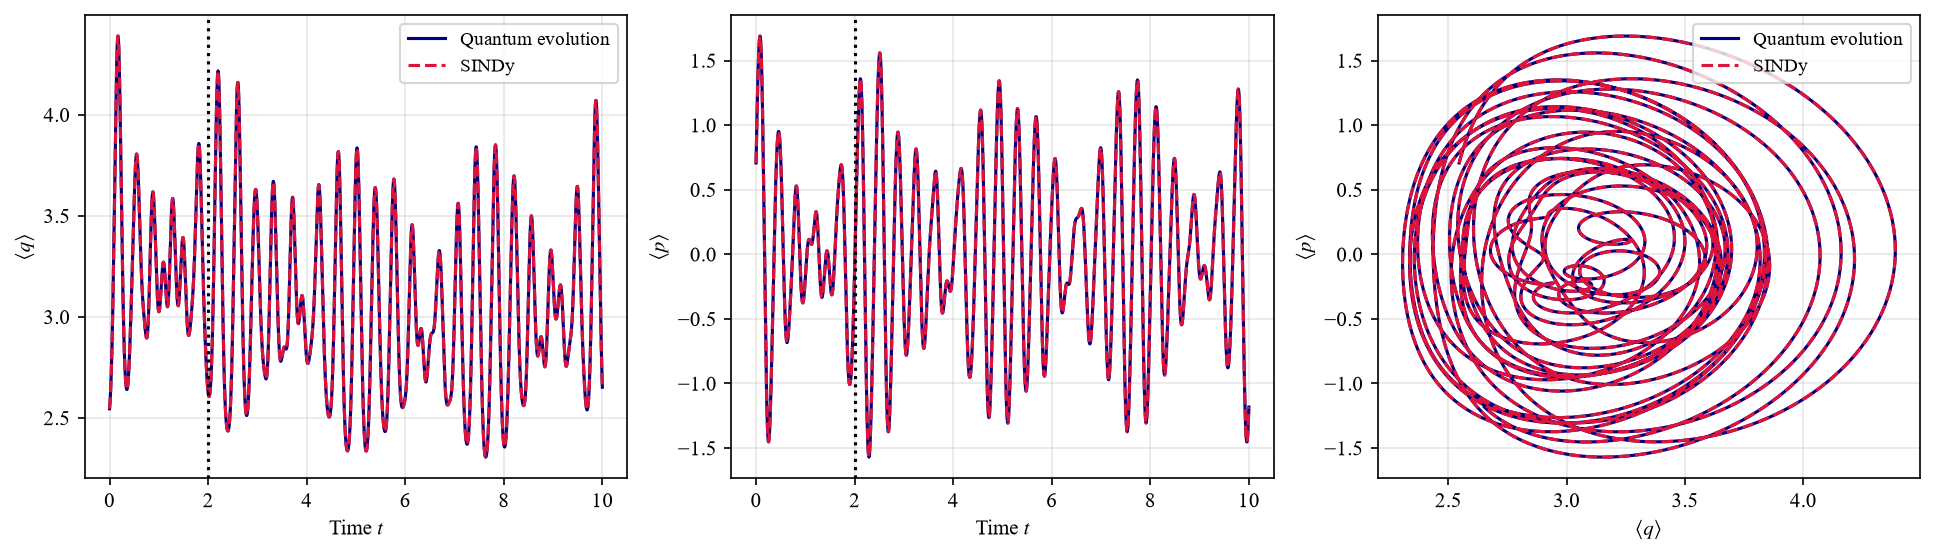

Maximum position error: 3.649877e-08
Maximum momentum error: 7.788562e-08


In [ ]:
#------------------------- Inputs -------------------------#
rtol = 1e-9
atol = 1e-11


#------------------------- Process -------------------------#
third_interpolator_qp = interp1d( times, exp_third, kind='cubic', bounds_error=True )

def sindy_qp_dynamics(t_value, state):

    third_value = third_interpolator_qp(t_value)

    theta_row, _ = build_qp_library( state[0], state[1], third_value )

    return (theta_row @ xi_qp)[0]

solution_qp = solve_ivp(
    sindy_qp_dynamics,
    t_span=(times[0], times[-1]),
    y0=[exp_q[0], exp_p[0]],
    t_eval=times,
    method='DOP853',
    rtol=rtol,
    atol=atol
    )

if not solution_qp.success:
    raise RuntimeError(solution_qp.message)

q_sindy = solution_qp.y[0]
p_sindy = solution_qp.y[1]


#------------------------- Outputs -------------------------#
fig, axes = plt.subplots(1, 3, figsize=(13.0, 3.8), dpi=150)

axes[0].plot(times, exp_q, color='navy', label='Quantum evolution')
axes[0].plot(times, q_sindy, '--', color='crimson', label='SINDy')
axes[0].set_xlabel(r'Time $t$')
axes[0].set_ylabel(r'$\langle q\rangle$')
axes[0].legend()

axes[1].plot(times, exp_p, color='navy')
axes[1].plot(times, p_sindy, '--', color='crimson')
axes[1].set_xlabel(r'Time $t$')
axes[1].set_ylabel(r'$\langle p\rangle$')

axes[2].plot(exp_q, exp_p, color='navy', label='Quantum evolution')
axes[2].plot(q_sindy, p_sindy, '--', color='crimson', label='SINDy')
axes[2].set_xlabel(r'$\langle q\rangle$')
axes[2].set_ylabel(r'$\langle p\rangle$')
axes[2].legend()

for ax in axes[:2]:
    ax.axvline(t_train_max, color='black', linestyle=':')

for ax in axes:
    ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

print(f"Maximum position error: {np.max(np.abs(q_sindy - exp_q)):.6e}")
print(f"Maximum momentum error: {np.max(np.abs(p_sindy - exp_p)):.6e}")

#### ~ $\mu_2$ & $\mu_3$

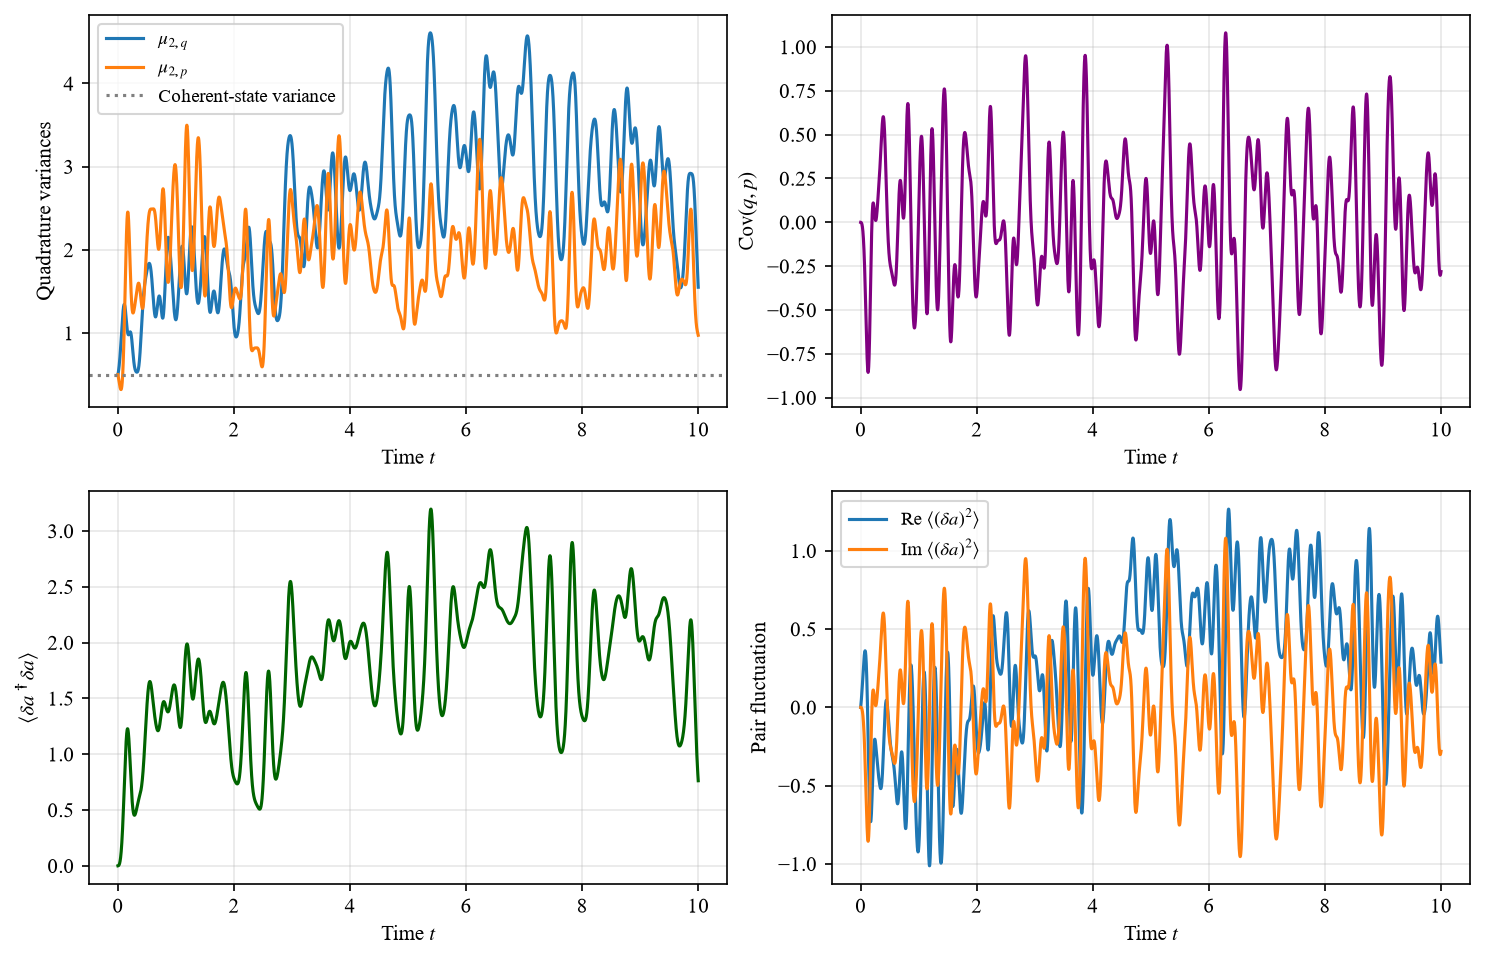

Initial position variance: 0.50000000
Initial momentum variance: 0.50000000
Initial covariance: 0.00000000


In [ ]:
#------------------------- Second-order moments -------------------------#
figure_size = (10.0, 6.5)


#------------------------- Process -------------------------#
# Quadrature operators
q_moment_op = (a_op + adag_op) / np.sqrt(2.0)
p_moment_op = (a_op - adag_op) / (1j * np.sqrt(2.0))

# Bosonic expectation values
mean_a_mom = expectation_value(a_op)
mean_a2_mom = expectation_value(a_op @ a_op)
mean_n_mom = expectation_value(adag_op @ a_op).real

# Centered bosonic correlations
fluctuation_number = mean_n_mom - np.abs(mean_a_mom)**2
fluctuation_pair = mean_a2_mom - mean_a_mom**2

# Quadrature means and second moments
mean_q_mom = np.sqrt(2.0) * mean_a_mom.real
mean_p_mom = np.sqrt(2.0) * mean_a_mom.imag

mean_q2_mom = expectation_value(q_moment_op @ q_moment_op).real
mean_p2_mom = expectation_value(p_moment_op @ p_moment_op).real

mu2_q = mean_q2_mom - mean_q_mom**2
mu2_p = mean_p2_mom - mean_p_mom**2

# Symmetrized covariance
qp_symmetric_op = ( q_moment_op @ p_moment_op + p_moment_op @ q_moment_op ) / 2.0

covariance_qp = ( expectation_value(qp_symmetric_op).real - mean_q_mom * mean_p_mom )


#------------------------- Outputs -------------------------#
fig, axes = plt.subplots(2, 2, figsize=figure_size, dpi=150)

axes[0, 0].plot(times, mu2_q, label=r'$\mu_{2,q}$')
axes[0, 0].plot(times, mu2_p, label=r'$\mu_{2,p}$')
axes[0, 0].axhline( 0.5, color='gray', linestyle=':', label='Coherent-state variance' )
axes[0, 0].set_ylabel('Quadrature variances')
axes[0, 0].legend()

axes[0, 1].plot(times, covariance_qp, color='purple')
axes[0, 1].set_ylabel(r'$\mathrm{Cov}(q,p)$')

axes[1, 0].plot(times, fluctuation_number, color='darkgreen')
axes[1, 0].set_ylabel(r'$\langle\delta a^\dagger\delta a\rangle$')

axes[1, 1].plot( times, fluctuation_pair.real, label=r'Re $\langle(\delta a)^2\rangle$' )
axes[1, 1].plot( times, fluctuation_pair.imag, label=r'Im $\langle(\delta a)^2\rangle$' )
axes[1, 1].set_ylabel('Pair fluctuation')
axes[1, 1].legend()

for ax in axes.flat:
    ax.set_xlabel(r'Time $t$')
    ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

print(f"Initial position variance: {mu2_q[0]:.8f}")
print(f"Initial momentum variance: {mu2_p[0]:.8f}")
print(f"Initial covariance: {covariance_qp[0]:.8f}")

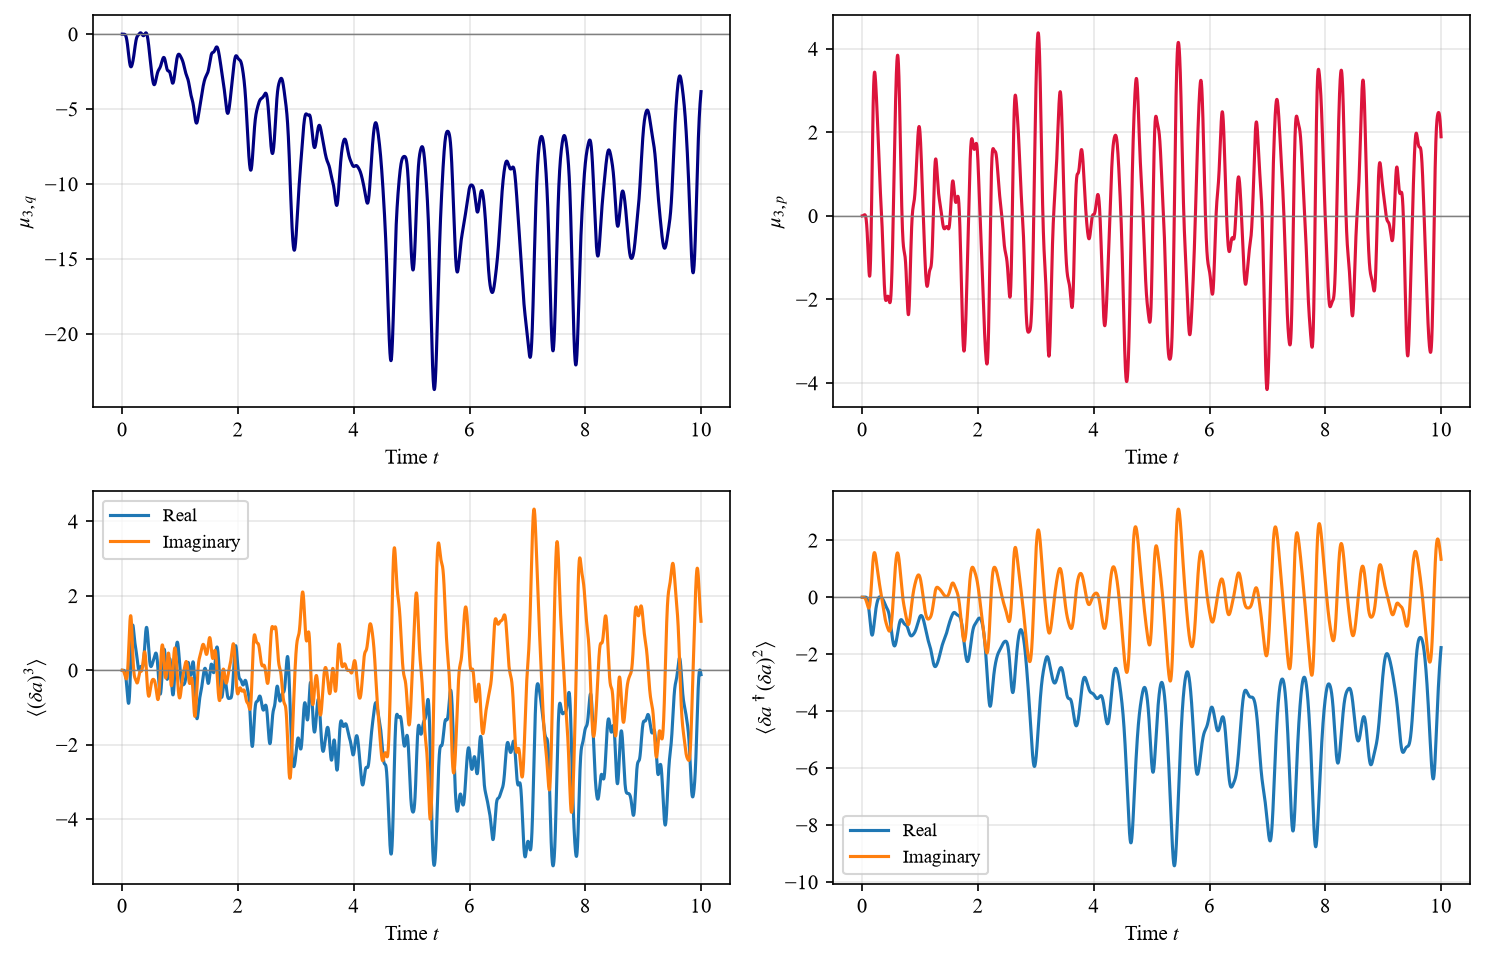

Initial position third central moment: 7.10542736e-15
Initial momentum third central moment: 1.33226763e-15


In [ ]:
#------------------------- Third-order moments -------------------------#
figure_size = (10.0, 6.5)


#------------------------- Process -------------------------#
# Raw third-order expectation values
mean_a3_mom = expectation_value(a_op @ a_op @ a_op)

mean_third_mom = expectation_value( adag_op @ a_op @ a_op )

# Centered bosonic third-order correlations
third_pure_centered = ( mean_a3_mom - 3.0 * mean_a_mom * mean_a2_mom + 2.0 * mean_a_mom**3 )

third_mixed_centered = ( mean_third_mom - mean_a_mom.conj() * mean_a2_mom - 2.0 * mean_a_mom * mean_n_mom + 2.0 * np.abs(mean_a_mom)**2 * mean_a_mom )

# Quadrature third moments
mean_q3_mom = expectation_value( q_moment_op @ q_moment_op @ q_moment_op ).real

mean_p3_mom = expectation_value(p_moment_op @ p_moment_op @ p_moment_op ).real

mu3_q = ( mean_q3_mom - 3.0 * mean_q_mom * mean_q2_mom + 2.0 * mean_q_mom**3 )

mu3_p = ( mean_p3_mom - 3.0 * mean_p_mom * mean_p2_mom + 2.0 * mean_p_mom**3 )


#------------------------- Outputs -------------------------#
fig, axes = plt.subplots(2, 2, figsize=figure_size, dpi=150)

axes[0, 0].plot(times, mu3_q, color='navy')
axes[0, 0].set_ylabel(r'$\mu_{3,q}$')

axes[0, 1].plot(times, mu3_p, color='crimson')
axes[0, 1].set_ylabel(r'$\mu_{3,p}$')

axes[1, 0].plot(times, third_pure_centered.real, label='Real' )
axes[1, 0].plot( times, third_pure_centered.imag, label='Imaginary' )
axes[1, 0].set_ylabel(r'$\langle(\delta a)^3\rangle$')
axes[1, 0].legend()

axes[1, 1].plot( times, third_mixed_centered.real, label='Real' )
axes[1, 1].plot( times, third_mixed_centered.imag, label='Imaginary' )
axes[1, 1].set_ylabel( r'$\langle\delta a^\dagger(\delta a)^2\rangle$' )
axes[1, 1].legend()

for ax in axes.flat:
    ax.set_xlabel(r'Time $t$')
    ax.axhline(0.0, color='gray', linewidth=0.7)
    ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

print(f"Initial position third central moment: {mu3_q[0]:.8e}")
print(f"Initial momentum third central moment: {mu3_p[0]:.8e}")